# Amazon Product Intelligence Platform
## Sentiment Analysis: Model Development

This notebook generates sentiment pseudo-labels, validates them manually, compares multiple models, performs grid-search fine-tuning and saves the final sentiment inference pipeline.

In [1]:
!pip install -q transformers accelerate

In [2]:
from google.colab import drive
from pathlib import Path

import json
import random
import numpy as np
import pandas as pd
import torch
import transformers

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MANUAL_LABEL_DIR = PROJECT_ROOT / "data" / "manual_labels"
MODEL_DIR = PROJECT_ROOT / "models" / "sentiment"
REPORT_DIR = PROJECT_ROOT / "reports" / "sentiment"

for folder in [
    PROCESSED_DIR,
    MANUAL_LABEL_DIR,
    MODEL_DIR,
    REPORT_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

REVIEWS_CLEAN_PATH = (
    PROCESSED_DIR
    / "reviews_clean.csv"
)

##Configure reproducibility

This keeps sampling, splitting and model-development results reproducible.

In [4]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


##Confirm GPU availability

In [5]:
if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is not enabled. Select Runtime > "
        "Change runtime type > GPU."
    )

DEVICE_NAME = torch.cuda.get_device_name(0)

print("GPU available:", torch.cuda.is_available())
print("GPU:", DEVICE_NAME)
print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)

GPU available: True
GPU: Tesla T4
PyTorch version: 2.11.0+cu128
Transformers version: 5.15.1


##Load the clean review dataset

This loads the output produced by the preprocessing notebook.

In [6]:
if not REVIEWS_CLEAN_PATH.exists():
    raise FileNotFoundError(
        f"Clean review dataset not found: "
        f"{REVIEWS_CLEAN_PATH}"
    )

reviews_clean = pd.read_csv(
    REVIEWS_CLEAN_PATH,
    dtype={
        "asin": str,
        "review_id": str
    },
    keep_default_na=False
)

print("Loaded review rows:", len(reviews_clean))
display(reviews_clean.head(3))

Loaded review rows: 7595


,asin,keyword,category,product_title,product_url,review_id,review_id_generated,reviewer_name,headline,review_text_raw,...,review_rating_raw,review_date,review_date_raw,usable_for_sentiment,text_character_count,text_word_count,shared_across_asins,asin_count_for_review,shared_asins,review_content_conflict
0,B0H9LHWBDK,wireless earbuds,wireless earbuds,"Wireless Earbuds, 2026 Bluetooth 5.4 Headphone...",https://www.amazon.com/dp/B0H9LHWBDK,R2CEXJGANFZ5NU,False,diamela,Great earbuds for the price,I’m really happy with these earbuds. The sound...,...,5.0 out of 5 stars,2026-08-18,"Reviewed in the United States on August 18, 2026",True,459,85,False,1,"[""B0H9LHWBDK""]",False
1,B0H9LHWBDK,wireless earbuds,wireless earbuds,"Wireless Earbuds, 2026 Bluetooth 5.4 Headphone...",https://www.amazon.com/dp/B0H9LHWBDK,R5VDNB3U3J2X2,False,Shakira Peñas,Recommended,These wireless earbuds have excellent sound qu...,...,5.0 out of 5 stars,2026-08-23,"Reviewed in the United States on August 23, 2026",True,476,74,False,1,"[""B0H9LHWBDK""]",False
2,B0H9LHWBDK,wireless earbuds,wireless earbuds,"Wireless Earbuds, 2026 Bluetooth 5.4 Headphone...",https://www.amazon.com/dp/B0H9LHWBDK,R1SXLCYBW5CNNX,False,Yuriko Matsumoto,Audífonos,I’m really impressed with these wireless earbu...,...,5.0 out of 5 stars,2026-08-24,"Reviewed in the United States on August 24, 2026",True,502,88,False,1,"[""B0H9LHWBDK""]",False


##Prepare unique reviews for labeling

Reviews shared across Amazon variants must be labelled once. Their prediction can later be merged back into every associated product using review_id.

In [7]:
usable_mask = (
    reviews_clean["usable_for_sentiment"]
    .astype(str)
    .str.lower()
    .eq("true")
)

reviews_for_labeling = (
    reviews_clean[usable_mask]
    .drop_duplicates(
        subset=["review_id"],
        keep="first"
    )
    .copy()
    .reset_index(drop=True)
)

LABEL_INPUT_COLUMNS = [
    "review_id",
    "asin",
    "category",
    "review_rating",
    "model_text",
    "text_word_count",
    "shared_across_asins",
    "asin_count_for_review"
]

reviews_for_labeling = reviews_for_labeling[
    LABEL_INPUT_COLUMNS
]

print(
    "Unique reviews prepared for labeling:",
    len(reviews_for_labeling)
)

Unique reviews prepared for labeling: 6486


##Validate the labeling input

These checks prevent duplicated reviews or empty text from reaching RoBERTa.

In [8]:
labeling_input_checks = {
    "Review IDs are unique":
        reviews_for_labeling["review_id"].is_unique,

    "Every review has an ID":
        reviews_for_labeling["review_id"]
        .str.strip()
        .ne("")
        .all(),

    "Every review has model text":
        reviews_for_labeling["model_text"]
        .str.strip()
        .ne("")
        .all(),

    "Every review has a category":
        reviews_for_labeling["category"]
        .str.strip()
        .ne("")
        .all()
}

for check, passed in labeling_input_checks.items():
    print(
        f"{'PASS' if passed else 'FAIL'}: {check}"
    )

assert all(labeling_input_checks.values())

PASS: Review IDs are unique
PASS: Every review has an ID
PASS: Every review has model text
PASS: Every review has a category


##Save the exact labeling input

This creates a reproducible record of exactly which reviews were sent to the labeling model.

In [9]:
LABEL_INPUT_PATH = (
    PROCESSED_DIR
    / "reviews_for_labeling.csv"
)

reviews_for_labeling.to_csv(
    LABEL_INPUT_PATH,
    index=False,
    encoding="utf-8-sig"
)

print(
    f"Labeling input saved to: "
    f"{LABEL_INPUT_PATH}"
)

Labeling input saved to: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/reviews_for_labeling.csv


### Model-development setup

- GPU acceleration was enabled for transformer inference.
- The cleaned dataset was loaded from the preprocessing pipeline.
- Reviews shared across multiple ASINs were reduced to one unique record per review ID for labeling.
- This prevents Amazon variant sharing from biasing label distribution and model training.
- The resulting labeling dataset contains 6,486 unique reviews.
- CardiffNLP RoBERTa will be used as a pseudo-labeling model, not automatically treated as unquestionable ground truth.
- Because the labeling model was developed using Twitter data, its predictions must be evaluated against manually checked Amazon reviews.

##Load the tokenizer and model

In [10]:
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    pipeline
)

MODEL_NAME = (
    "cardiffnlp/"
    "twitter-roberta-base-sentiment-latest"
)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

labeling_model = (
    AutoModelForSequenceClassification
    .from_pretrained(MODEL_NAME)
    .to("cuda")
)

labeling_model.eval()

MAX_LENGTH = min(
    tokenizer.model_max_length,
    512
)

BATCH_SIZE = 16

print("Model:", MODEL_NAME)
print("Maximum tokens:", MAX_LENGTH)
print("Batch size:", BATCH_SIZE)
print("Label mapping:", labeling_model.config.id2label)

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

Model: cardiffnlp/twitter-roberta-base-sentiment-latest
Maximum tokens: 512
Batch size: 16
Label mapping: {0: 'negative', 1: 'neutral', 2: 'positive'}


##Create the GPU classification pipeline

We will request all three probability scores, not only the winning label.

In [11]:
sentiment_classifier = pipeline(
    task="text-classification",
    model=labeling_model,
    tokenizer=tokenizer,
    device=0
)

print("Sentiment pipeline loaded on GPU.")

Sentiment pipeline loaded on GPU.


##Test the model before processing everything

This smoke test verifies that the model returns the expected labels.

In [12]:
test_reviews = [
    "Excellent sound quality and battery life.",
    "The product is okay, nothing particularly special.",
    "It stopped working after only two days."
]

test_predictions = sentiment_classifier(
    test_reviews,
    top_k=None,
    truncation=True,
    max_length=MAX_LENGTH
)

for text, predictions in zip(
    test_reviews,
    test_predictions
):
    print("\nText:", text)

    for prediction in predictions:
        print(
            prediction["label"],
            round(prediction["score"], 4)
        )


Text: Excellent sound quality and battery life.
positive 0.961
neutral 0.0324
negative 0.0066

Text: The product is okay, nothing particularly special.
neutral 0.575
positive 0.2231
negative 0.2019

Text: It stopped working after only two days.
negative 0.7797
neutral 0.2077
positive 0.0126


##Define the prediction formatter

This converts the model output into consistent columns.

In [13]:
EXPECTED_LABELS = {
    "negative",
    "neutral",
    "positive"
}


def format_prediction(
    review_id,
    raw_prediction,
    token_count
):
    score_map = {
        str(item["label"]).lower():
        float(item["score"])
        for item in raw_prediction
    }

    missing_labels = (
        EXPECTED_LABELS - set(score_map)
    )

    if missing_labels:
        raise ValueError(
            f"Model output is missing labels: "
            f"{missing_labels}"
        )

    ranked_scores = sorted(
        score_map.items(),
        key=lambda item: item[1],
        reverse=True
    )

    predicted_label = ranked_scores[0][0]
    confidence = ranked_scores[0][1]
    confidence_margin = (
        ranked_scores[0][1]
        - ranked_scores[1][1]
    )

    return {
        "review_id": review_id,
        "pseudo_label": predicted_label,
        "pseudo_confidence": confidence,
        "confidence_margin": confidence_margin,
        "negative_score": score_map["negative"],
        "neutral_score": score_map["neutral"],
        "positive_score": score_map["positive"],
        "original_token_count": token_count,
        "text_truncated": token_count > MAX_LENGTH,
        "label_model": MODEL_NAME
    }

##Configure batching and checkpoints

Hugging Face supports batch inference, although the best batch size depends on GPU memory and text length. Hugging Face pipeline documentation

A batch size of 16 is a safe starting point for a Colab T4 GPU.

In [14]:
from tqdm.auto import tqdm

BATCH_SIZE = 16
CHECKPOINT_EVERY_BATCHES = 20

CHECKPOINT_PATH = (
    PROCESSED_DIR
    / "roberta_labeling_checkpoint.csv"
)

PSEUDO_LABEL_PATH = (
    PROCESSED_DIR
    / "reviews_pseudo_labeled.csv"
)

print("Batch size:", BATCH_SIZE)
print("Checkpoint:", CHECKPOINT_PATH)

Batch size: 16
Checkpoint: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/roberta_labeling_checkpoint.csv


##Load an existing checkpoint if available

This allows labeling to continue after an interrupted Colab session.

In [15]:
if CHECKPOINT_PATH.exists():
    checkpoint_predictions = pd.read_csv(
        CHECKPOINT_PATH,
        dtype={"review_id": str}
    )

    if not checkpoint_predictions[
        "label_model"
    ].eq(MODEL_NAME).all():
        raise ValueError(
            "The checkpoint was generated using "
            "a different labeling model."
        )

    checkpoint_predictions = (
        checkpoint_predictions
        .drop_duplicates(
            subset=["review_id"],
            keep="last"
        )
    )

    print(
        "Predictions restored:",
        len(checkpoint_predictions)
    )

else:
    checkpoint_predictions = pd.DataFrame()

    print("No checkpoint found. Starting fresh.")

Predictions restored: 6486


In [16]:
completed_review_ids = set(
    checkpoint_predictions.get(
        "review_id",
        pd.Series(dtype=str)
    )
)

remaining_reviews = reviews_for_labeling[
    ~reviews_for_labeling["review_id"].isin(
        completed_review_ids
    )
].copy()

print(
    "Reviews remaining:",
    len(remaining_reviews)
)

Reviews remaining: 0


##Run batched pseudo-labeling

This is the main GPU inference step. Depending on the GPU and review lengths, it may take several minutes

In [17]:
prediction_parts = []

if not checkpoint_predictions.empty:
    prediction_parts.append(
        checkpoint_predictions
    )

batch_starts = range(
    0,
    len(remaining_reviews),
    BATCH_SIZE
)

for batch_number, start in enumerate(
    tqdm(
        batch_starts,
        desc="Generating pseudo-labels"
    ),
    start=1
):
    batch = remaining_reviews.iloc[
        start:start + BATCH_SIZE
    ]

    batch_texts = (
        batch["model_text"]
        .astype(str)
        .tolist()
    )

    tokenized_batch = tokenizer(
        batch_texts,
        add_special_tokens=True,
        truncation=False,
        padding=False,
        return_length=True,
        verbose=False
    )

    token_lengths = tokenized_batch["length"]

    batch_predictions = sentiment_classifier(
        batch_texts,
        top_k=None,
        batch_size=BATCH_SIZE,
        truncation=True,
        max_length=MAX_LENGTH
    )

    formatted_batch = [
        format_prediction(
            review_id=review_id,
            raw_prediction=prediction,
            token_count=token_count
        )
        for review_id, prediction, token_count
        in zip(
            batch["review_id"],
            batch_predictions,
            token_lengths
        )
    ]

    prediction_parts.append(
        pd.DataFrame(formatted_batch)
    )

    if (
        batch_number
        % CHECKPOINT_EVERY_BATCHES
        == 0
    ):
        current_predictions = (
            pd.concat(
                prediction_parts,
                ignore_index=True
            )
            .drop_duplicates(
                subset=["review_id"],
                keep="last"
            )
        )

        current_predictions.to_csv(
            CHECKPOINT_PATH,
            index=False,
            encoding="utf-8-sig"
        )

Generating pseudo-labels: 0it [00:00, ?it/s]

##Combine and validate predictions

In [18]:
pseudo_predictions = (
    pd.concat(
        prediction_parts,
        ignore_index=True
    )
    .drop_duplicates(
        subset=["review_id"],
        keep="last"
    )
    .reset_index(drop=True)
)

assert pseudo_predictions["review_id"].is_unique

assert (
    len(pseudo_predictions)
    == len(reviews_for_labeling)
)

assert set(
    pseudo_predictions["pseudo_label"]
).issubset(EXPECTED_LABELS)

probability_sum = (
    pseudo_predictions[
        [
            "negative_score",
            "neutral_score",
            "positive_score"
        ]
    ]
    .sum(axis=1)
)

assert np.allclose(
    probability_sum,
    1.0,
    atol=1e-4
)

print(
    "Successfully labelled reviews:",
    len(pseudo_predictions)
)

Successfully labelled reviews: 6486


##Merge labels with review information

In [19]:
reviews_pseudo_labeled = (
    reviews_for_labeling
    .merge(
        pseudo_predictions,
        on="review_id",
        how="left",
        validate="one_to_one"
    )
)

assert reviews_pseudo_labeled[
    "pseudo_label"
].notna().all()

display(
    reviews_pseudo_labeled[
        [
            "review_id",
            "model_text",
            "pseudo_label",
            "pseudo_confidence",
            "text_truncated"
        ]
    ].head()
)

,review_id,model_text,pseudo_label,pseudo_confidence,text_truncated
0,R2CEXJGANFZ5NU,Great earbuds for the price I’m really happy w...,positive,0.977362,False
1,R5VDNB3U3J2X2,Recommended These wireless earbuds have excell...,positive,0.958551,False
2,R1SXLCYBW5CNNX,Audífonos I’m really impressed with these wire...,positive,0.985280,False
3,R371NFF0G5D0P1,Comfortably I’m really happy with these wirele...,positive,0.980531,False
4,R24STKYGFHNIN4,Great Value Wireless Earbuds I’m pleasantly su...,positive,0.979043,False


In [20]:
PSEUDO_LABEL_OUTPUT_PATH = (
    PROCESSED_DIR
    / "reviews_pseudo_labeled.csv"
)

CHECKPOINT_PATH = (
    PROCESSED_DIR
    / "roberta_labeling_checkpoint.csv"
)

print(PSEUDO_LABEL_OUTPUT_PATH)

/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/reviews_pseudo_labeled.csv


In [21]:
reviews_pseudo_labeled.to_csv(
    PSEUDO_LABEL_OUTPUT_PATH,
    index=False,
    encoding="utf-8-sig"
)

print(
    f"Pseudo-labelled dataset saved to: "
    f"{PSEUDO_LABEL_OUTPUT_PATH}"
)

Pseudo-labelled dataset saved to: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/reviews_pseudo_labeled.csv


In [22]:
print(
    "Pseudo-labelled file exists:",
    PSEUDO_LABEL_OUTPUT_PATH.exists()
)

print(
    "Saved location:",
    PSEUDO_LABEL_OUTPUT_PATH
)

Pseudo-labelled file exists: True
Saved location: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/reviews_pseudo_labeled.csv


In [23]:
from pathlib import Path
import json
import pandas as pd
import torch
import transformers

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models" / "sentiment"

PSEUDO_LABEL_OUTPUT_PATH = (
    PROCESSED_DIR
    / "reviews_pseudo_labeled.csv"
)

CHECKPOINT_PATH = (
    PROCESSED_DIR
    / "roberta_labeling_checkpoint.csv"
)

LABELING_METADATA_PATH = (
    MODEL_DIR
    / "pseudo_labeling_metadata.json"
)

MODEL_NAME = (
    "cardiffnlp/"
    "twitter-roberta-base-sentiment-latest"
)

LOW_CONFIDENCE_THRESHOLD = 0.65
MAX_LENGTH = 512
BATCH_SIZE = 16

# Load the saved labels if the DataFrame is unavailable.
if "reviews_pseudo_labeled" not in globals():
    reviews_pseudo_labeled = pd.read_csv(
        PSEUDO_LABEL_OUTPUT_PATH,
        dtype={"review_id": str}
    )

# Add the manual-review flag.
reviews_pseudo_labeled[
    "needs_manual_review"
] = (
    reviews_pseudo_labeled[
        "pseudo_confidence"
    ].lt(LOW_CONFIDENCE_THRESHOLD)
    | reviews_pseudo_labeled[
        "text_truncated"
    ].astype(str).str.lower().eq("true")
)

# Save the final labelled dataset.
reviews_pseudo_labeled.to_csv(
    PSEUDO_LABEL_OUTPUT_PATH,
    index=False,
    encoding="utf-8-sig"
)

# Reconstruct and save the complete checkpoint.
PREDICTION_COLUMNS = [
    "review_id",
    "pseudo_label",
    "pseudo_confidence",
    "confidence_margin",
    "negative_score",
    "neutral_score",
    "positive_score",
    "original_token_count",
    "text_truncated",
    "label_model"
]

final_checkpoint = reviews_pseudo_labeled[
    PREDICTION_COLUMNS
].copy()

final_checkpoint.to_csv(
    CHECKPOINT_PATH,
    index=False,
    encoding="utf-8-sig"
)

device_name = (
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "CPU"
)

labeling_metadata = {
    "model_name": MODEL_NAME,
    "model_label_mapping": {
        "0": "negative",
        "1": "neutral",
        "2": "positive"
    },
    "maximum_token_length": MAX_LENGTH,
    "batch_size": BATCH_SIZE,
    "unique_reviews_labeled": len(
        reviews_pseudo_labeled
    ),
    "low_confidence_threshold": (
        LOW_CONFIDENCE_THRESHOLD
    ),
    "transformers_version": (
        transformers.__version__
    ),
    "pytorch_version": torch.__version__,
    "gpu": device_name,
    "generated_at_utc": pd.Timestamp.now(
        tz="UTC"
    ).isoformat()
}

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

with open(
    LABELING_METADATA_PATH,
    "w",
    encoding="utf-8"
) as metadata_file:
    json.dump(
        labeling_metadata,
        metadata_file,
        indent=2
    )

print("Finalization successful")
print(
    "Pseudo-labelled rows:",
    len(reviews_pseudo_labeled)
)
print(
    "Checkpoint rows:",
    len(final_checkpoint)
)
print(
    "Manual-review candidates:",
    reviews_pseudo_labeled[
        "needs_manual_review"
    ].sum()
)
print(
    "Labelled dataset:",
    PSEUDO_LABEL_OUTPUT_PATH
)
print(
    "Metadata:",
    LABELING_METADATA_PATH
)

Finalization successful
Pseudo-labelled rows: 6486
Checkpoint rows: 6486
Manual-review candidates: 1031
Labelled dataset: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/reviews_pseudo_labeled.csv
Metadata: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/sentiment/pseudo_labeling_metadata.json


### Pseudo-labeling methodology

- CardiffNLP Twitter-RoBERTa was used as a teacher model to generate initial negative, neutral and positive labels.
- Every unique review ID was labelled once to prevent product-variant duplication from influencing the class distribution.
- All three class probabilities were preserved for transparency and later error analysis.
- Reviews exceeding the tokenizer limit were truncated and explicitly flagged.
- Low-confidence and truncated reviews were prioritized for manual review.
- The generated labels are pseudo-labels rather than ground-truth labels.
- Model quality will be evaluated against a separate manually labelled Amazon-review sample.

##Load the finalized pseudo-labelled dataset

This cell is self-contained and uses the saved output, so it does not depend on the earlier inference variables.

In [24]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MANUAL_LABEL_DIR = PROJECT_ROOT / "data" / "manual_labels"
REPORT_DIR = PROJECT_ROOT / "reports" / "sentiment"
FIGURE_DIR = REPORT_DIR / "figures"

for folder in [
    MANUAL_LABEL_DIR,
    REPORT_DIR,
    FIGURE_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

PSEUDO_LABEL_PATH = (
    PROCESSED_DIR
    / "reviews_pseudo_labeled.csv"
)

reviews_labeled = pd.read_csv(
    PSEUDO_LABEL_PATH,
    dtype={"review_id": str},
    keep_default_na=False
)

print("Pseudo-labelled reviews:", len(reviews_labeled))

Pseudo-labelled reviews: 6486


##Normalize the analysis fields

CSV files may reload Boolean and numeric values as text. This cell restores the correct types.

In [25]:
reviews_labeled["pseudo_label"] = (
    reviews_labeled["pseudo_label"]
    .astype(str)
    .str.strip()
    .str.lower()
)

NUMERIC_COLUMNS = [
    "review_rating",
    "pseudo_confidence",
    "confidence_margin",
    "negative_score",
    "neutral_score",
    "positive_score",
    "original_token_count"
]

for column in NUMERIC_COLUMNS:
    reviews_labeled[column] = pd.to_numeric(
        reviews_labeled[column],
        errors="coerce"
    )

BOOLEAN_COLUMNS = [
    "text_truncated",
    "needs_manual_review"
]

for column in BOOLEAN_COLUMNS:
    reviews_labeled[column] = (
        reviews_labeled[column]
        .astype(str)
        .str.lower()
        .eq("true")
    )

assert len(reviews_labeled) == 6486
assert reviews_labeled["review_id"].is_unique
assert reviews_labeled["pseudo_label"].notna().all()

print("Analysis fields validated.")

Analysis fields validated.


##Analyze the pseudo-label distribution

This determines whether the RoBERTa labels are imbalanced.

In [26]:
LABEL_ORDER = [
    "negative",
    "neutral",
    "positive"
]

label_distribution = (
    reviews_labeled["pseudo_label"]
    .value_counts()
    .reindex(LABEL_ORDER, fill_value=0)
    .rename_axis("pseudo_label")
    .reset_index(name="review_count")
)

label_distribution["percentage"] = (
    label_distribution["review_count"]
    / label_distribution["review_count"].sum()
    * 100
).round(2)

display(label_distribution)

,pseudo_label,review_count,percentage
0,negative,422,6.51
1,neutral,343,5.29
2,positive,5721,88.21


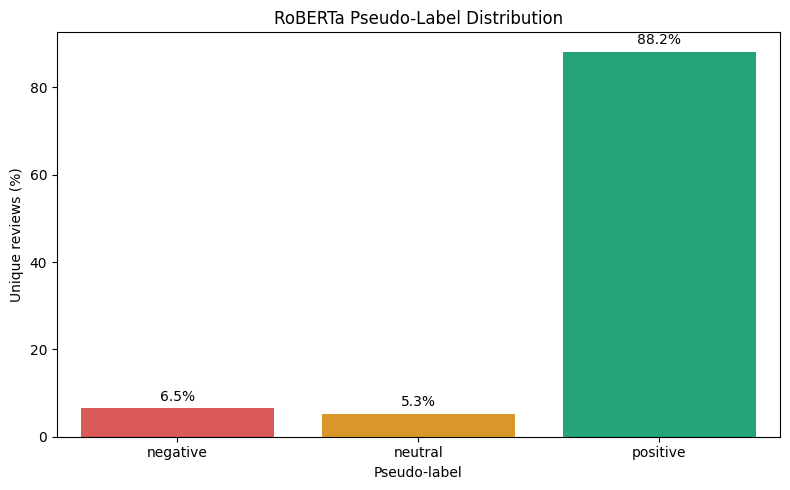

In [27]:
label_colors = {
    "negative": "#EF4444",
    "neutral": "#F59E0B",
    "positive": "#10B981"
}

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=label_distribution,
    x="pseudo_label",
    y="percentage",
    hue="pseudo_label",
    palette=label_colors,
    legend=False
)

ax.set_title("RoBERTa Pseudo-Label Distribution")
ax.set_xlabel("Pseudo-label")
ax.set_ylabel("Unique reviews (%)")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "pseudo_label_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

label_distribution.to_csv(
    REPORT_DIR / "pseudo_label_distribution.csv",
    index=False
)

##Analyze model confidence

This shows whether neutral, negative or positive predictions have lower average confidence.

In [28]:
confidence_summary = (
    reviews_labeled
    .groupby("pseudo_label")
    .agg(
        review_count=(
            "review_id",
            "count"
        ),
        mean_confidence=(
            "pseudo_confidence",
            "mean"
        ),
        median_confidence=(
            "pseudo_confidence",
            "median"
        ),
        minimum_confidence=(
            "pseudo_confidence",
            "min"
        ),
        low_confidence_count=(
            "pseudo_confidence",
            lambda values:
            (values < 0.70).sum()
        )
    )
    .reindex(LABEL_ORDER)
    .reset_index()
)

display(confidence_summary.round(4))

,pseudo_label,review_count,mean_confidence,median_confidence,minimum_confidence,low_confidence_count
0,negative,422,0.7371,0.7729,0.3498,163
1,neutral,343,0.5815,0.5484,0.3599,274
2,positive,5721,0.9157,0.9615,0.3545,387


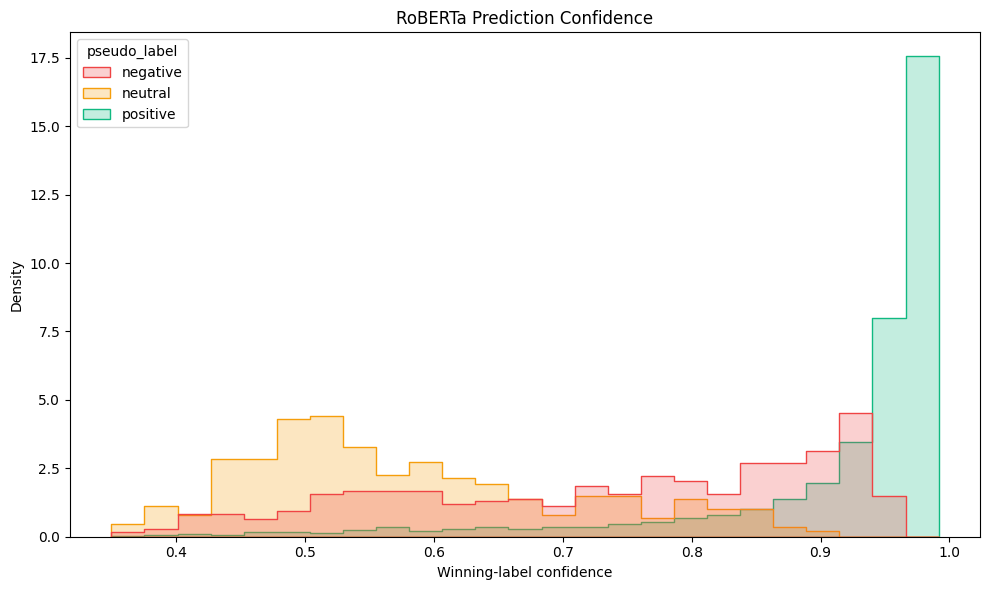

In [29]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=reviews_labeled,
    x="pseudo_confidence",
    hue="pseudo_label",
    hue_order=LABEL_ORDER,
    palette=label_colors,
    bins=25,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("RoBERTa Prediction Confidence")
plt.xlabel("Winning-label confidence")
plt.ylabel("Density")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "pseudo_label_confidence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

confidence_summary.to_csv(
    REPORT_DIR / "pseudo_label_confidence_summary.csv",
    index=False
)

##Analyze truncation and review flags

The 1,031 candidates represent the union of low-confidence and truncated reviews.

In [30]:
manual_review_summary = pd.DataFrame({
    "metric": [
        "Total unique reviews",
        "Low-confidence reviews",
        "Truncated reviews",
        "Manual-review candidates"
    ],
    "value": [
        len(reviews_labeled),
        (
            reviews_labeled[
                "pseudo_confidence"
            ] < 0.70
        ).sum(),
        reviews_labeled[
            "text_truncated"
        ].sum(),
        reviews_labeled[
            "needs_manual_review"
        ].sum()
    ]
})

manual_review_summary["percentage"] = (
    manual_review_summary["value"]
    / len(reviews_labeled)
    * 100
).round(2)

display(manual_review_summary)

,metric,value,percentage
0,Total unique reviews,6486,100.0
1,Low-confidence reviews,824,12.7
2,Truncated reviews,324,5.0
3,Manual-review candidates,1031,15.9


In [31]:
manual_review_summary.to_csv(
    REPORT_DIR / "manual_review_candidate_summary.csv",
    index=False
)

##Compare ratings with RoBERTa labels

Rating is not ground truth. This comparison only identifies potentially interesting disagreements.

In [32]:
reviews_labeled[
    "rating_sentiment_reference"
] = np.select(
    [
        reviews_labeled[
            "review_rating"
        ].between(1, 2),

        reviews_labeled[
            "review_rating"
        ].eq(3),

        reviews_labeled[
            "review_rating"
        ].between(4, 5)
    ],
    [
        "negative",
        "neutral",
        "positive"
    ],
    default="unknown"
)

reviews_labeled[
    "rating_label_agreement"
] = (
    reviews_labeled[
        "rating_sentiment_reference"
    ]
    == reviews_labeled["pseudo_label"]
)

agreement_summary = pd.DataFrame({
    "metric": [
        "Rating-label agreements",
        "Rating-label disagreements",
        "Agreement percentage"
    ],
    "value": [
        reviews_labeled[
            "rating_label_agreement"
        ].sum(),

        (
            ~reviews_labeled[
                "rating_label_agreement"
            ]
        ).sum(),

        reviews_labeled[
            "rating_label_agreement"
        ].mean() * 100
    ]
})

display(agreement_summary.round(2))

,metric,value
0,Rating-label agreements,5851.00
1,Rating-label disagreements,635.00
2,Agreement percentage,90.21


In [33]:
rating_label_table = pd.crosstab(
    reviews_labeled["review_rating"],
    reviews_labeled["pseudo_label"]
).reindex(
    columns=LABEL_ORDER,
    fill_value=0
)

display(rating_label_table)

pseudo_label,negative,neutral,positive
review_rating,,,
1.0,164,18,16
2.0,30,2,3
3.0,111,61,106
4.0,79,77,701
5.0,38,185,4895


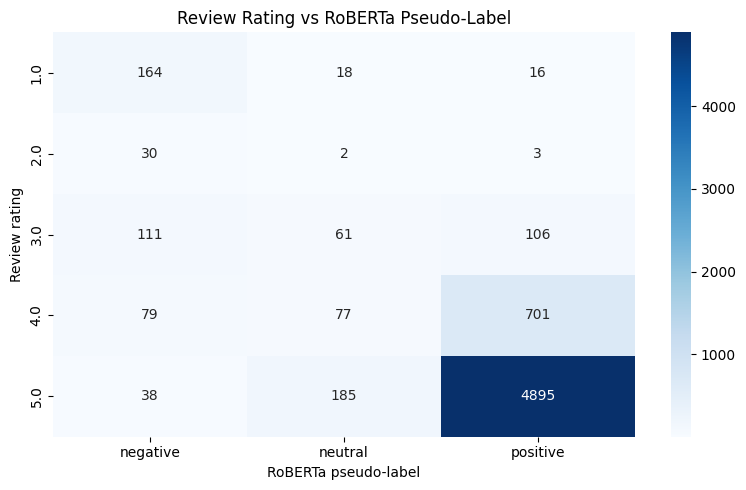

In [34]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    rating_label_table,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Review Rating vs RoBERTa Pseudo-Label")
plt.xlabel("RoBERTa pseudo-label")
plt.ylabel("Review rating")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "rating_vs_pseudo_label.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

rating_label_table.to_csv(
    REPORT_DIR / "rating_vs_pseudo_label.csv"
)

##Create a balanced manual-validation sample

We will manually label 300 reviews:

100 predicted negative
100 predicted neutral
100 predicted positive

This allows meaningful per-class precision, recall, F1 and confusion-matrix evaluation.

In [35]:
SEED = 42
REVIEWS_PER_CLASS = 100

class_counts = (
    reviews_labeled["pseudo_label"]
    .value_counts()
)

insufficient_classes = class_counts[
    class_counts < REVIEWS_PER_CLASS
]

if not insufficient_classes.empty:
    raise ValueError(
        "Not enough reviews for balanced sampling: "
        f"{insufficient_classes.to_dict()}"
    )

manual_reference = (
    reviews_labeled
    .groupby(
        "pseudo_label",
        group_keys=False
    )
    .sample(
        n=REVIEWS_PER_CLASS,
        random_state=SEED
    )
    .sample(
        frac=1,
        random_state=SEED
    )
    .reset_index(drop=True)
)

manual_reference.insert(
    0,
    "sample_id",
    [
        f"MVS-{number:04d}"
        for number in range(
            1,
            len(manual_reference) + 1
        )
    ]
)

print("Manual sample size:", len(manual_reference))

display(
    manual_reference[
        "pseudo_label"
    ].value_counts()
)

Manual sample size: 300


,count
pseudo_label,
positive,100
neutral,100
negative,100


##Create a blind annotation file

The blind file excludes RoBERTa labels, confidence scores and star ratings. This prevents those values from influencing your human judgment.

In [36]:
manual_blind = manual_reference[
    [
        "sample_id",
        "review_id",
        "category",
        "model_text"
    ]
].copy()

manual_blind["human_label"] = ""
manual_blind["annotation_notes"] = ""

BLIND_SAMPLE_PATH = (
    MANUAL_LABEL_DIR
    / "manual_validation_blind.csv"
)

REFERENCE_SAMPLE_PATH = (
    MANUAL_LABEL_DIR
    / "manual_validation_reference.csv"
)

manual_blind.to_csv(
    BLIND_SAMPLE_PATH,
    index=False,
    encoding="utf-8-sig"
)

manual_reference.to_csv(
    REFERENCE_SAMPLE_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Blind sample:", BLIND_SAMPLE_PATH)
print("Reference sample:", REFERENCE_SAMPLE_PATH)

Blind sample: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/manual_labels/manual_validation_blind.csv
Reference sample: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/manual_labels/manual_validation_reference.csv


In [37]:
from google.colab import files

files.download(str(BLIND_SAMPLE_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Pseudo-label analysis and manual-sampling interpretation

- RoBERTa pseudo-labels were analyzed for class balance, confidence and truncation.
- Rating-label disagreement was used only as an error-analysis signal because star ratings are not sentiment ground truth.
- Reviews were sampled equally from the three predicted classes to support meaningful per-class evaluation.
- The manual-labeling file hides model predictions, confidence scores and ratings to reduce annotation bias.
- The 300 manually reviewed examples will remain separate from model training and will serve as the final human-verified evaluation set.
- Because the evaluation sample is class-balanced, macro-F1 and per-class metrics will be emphasized. Accuracy will be reported with a clear note about the balanced sampling design.

In [38]:
from google.colab import files
from pathlib import Path

uploaded = files.upload()

uploaded_csv_files = [
    filename
    for filename in uploaded
    if filename.lower().endswith(".csv")
]

if len(uploaded_csv_files) != 1:
    raise ValueError(
        "Please upload exactly one completed CSV file."
    )

uploaded_filename = uploaded_csv_files[0]

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

MANUAL_LABEL_DIR = (
    PROJECT_ROOT
    / "data"
    / "manual_labels"
)

MANUAL_LABEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

COMPLETED_LABEL_PATH = (
    MANUAL_LABEL_DIR
    / "manual_validation_completed.csv"
)

COMPLETED_LABEL_PATH.write_bytes(
    uploaded[uploaded_filename]
)

print(
    "Completed manual labels saved to:",
    COMPLETED_LABEL_PATH
)

Saving manual_validation_completed.csv to manual_validation_completed.csv
Completed manual labels saved to: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/manual_labels/manual_validation_completed.csv


##Load the completed labels and hidden reference

The completed file contains your labels. The reference file contains RoBERTa’s predictions and confidence scores.

In [39]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    precision_recall_fscore_support
)

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

MANUAL_LABEL_DIR = (
    PROJECT_ROOT
    / "data"
    / "manual_labels"
)

REPORT_DIR = (
    PROJECT_ROOT
    / "reports"
    / "sentiment"
)

FIGURE_DIR = REPORT_DIR / "figures"

COMPLETED_LABEL_PATH = (
    MANUAL_LABEL_DIR
    / "manual_validation_completed.csv"
)

REFERENCE_LABEL_PATH = (
    MANUAL_LABEL_DIR
    / "manual_validation_reference.csv"
)

if not COMPLETED_LABEL_PATH.exists():
    raise FileNotFoundError(
        f"Completed manual-label file not found: "
        f"{COMPLETED_LABEL_PATH}"
    )

if not REFERENCE_LABEL_PATH.exists():
    raise FileNotFoundError(
        f"Reference file not found: "
        f"{REFERENCE_LABEL_PATH}"
    )

manual_completed = pd.read_csv(
    COMPLETED_LABEL_PATH,
    dtype={
        "sample_id": str,
        "review_id": str
    },
    keep_default_na=False
)

manual_reference = pd.read_csv(
    REFERENCE_LABEL_PATH,
    dtype={
        "sample_id": str,
        "review_id": str
    },
    keep_default_na=False
)

print("Completed labels:", len(manual_completed))
print("Reference rows:", len(manual_reference))

Completed labels: 300
Reference rows: 300


##Validate the human labels

This prevents blank, misspelled or duplicated labels from affecting evaluation.

In [41]:
VALID_LABELS = {
    "negative",
    "neutral",
    "positive"
}

REQUIRED_MANUAL_COLUMNS = {
    "sample_id",
    "review_id",
    "human_label"

}

missing_columns = (
    REQUIRED_MANUAL_COLUMNS
    - set(manual_completed.columns)
)

if missing_columns:
    raise ValueError(
        f"Missing manual-label columns: "
        f"{sorted(missing_columns)}"
    )

manual_completed["human_label"] = (
    manual_completed["human_label"]
    .astype(str)
    .str.strip()
    .str.lower()
)

invalid_label_mask = (
    ~manual_completed[
        "human_label"
    ].isin(VALID_LABELS)
)

invalid_labels = manual_completed.loc[
    invalid_label_mask,
    [
        "sample_id",
        "review_id",
        "human_label"
    ]
]

if not invalid_labels.empty:
    display(invalid_labels)

    raise ValueError(
        "Some human labels are blank or invalid. "
        "Use only positive, neutral or negative."
    )

assert manual_completed["sample_id"].is_unique
assert manual_completed["review_id"].is_unique

assert set(
    manual_completed["sample_id"]
) == set(
    manual_reference["sample_id"]
)

print("Manual-label validation successful.")

Manual-label validation successful.


##Merge human labels with RoBERTa predictions

Only the label and optional notes are taken from the completed blind file.

In [43]:
human_columns = manual_completed[
    [
        "sample_id",
        "review_id",
        "human_label",

    ]
]

manual_evaluation = (
    manual_reference
    .merge(
        human_columns,
        on=[
            "sample_id",
            "review_id"
        ],
        how="inner",
        validate="one_to_one"
    )
)

manual_evaluation["pseudo_label"] = (
    manual_evaluation["pseudo_label"]
    .astype(str)
    .str.strip()
    .str.lower()
)

manual_evaluation["prediction_correct"] = (
    manual_evaluation["pseudo_label"]
    == manual_evaluation["human_label"]
)

print(
    "Evaluation rows:",
    len(manual_evaluation)
)

display(
    manual_evaluation[
        [
            "sample_id",
            "model_text",
            "human_label",
            "pseudo_label",
            "pseudo_confidence",
            "prediction_correct"
        ]
    ].head()
)

Evaluation rows: 300


,sample_id,model_text,human_label,pseudo_label,pseudo_confidence,prediction_correct
0,MVS-0001,"Love this cute top This is a cute, long top th...",positive,positive,0.973610,True
1,MVS-0002,"Like it Charges very fast, good size and you c...",positive,positive,0.908095,True
2,MVS-0003,Good for High School or College The video show...,positive,neutral,0.679235,False
3,MVS-0004,Power selector cracks in a few weeks. Good lig...,negative,negative,0.690706,True
4,MVS-0005,Must have for acoustic guitar players I don’t ...,positive,positive,0.948336,True


##Calculate evaluation metrics

Because the sample was balanced by predicted class, macro-F1 and per-class metrics are particularly important.

In [44]:
y_true = manual_evaluation["human_label"]
y_pred = manual_evaluation["pseudo_label"]

accuracy = accuracy_score(
    y_true,
    y_pred
)

balanced_accuracy = balanced_accuracy_score(
    y_true,
    y_pred
)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[
            "negative",
            "neutral",
            "positive"
        ],
        average="macro",
        zero_division=0
    )
)

weighted_f1 = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[
            "negative",
            "neutral",
            "positive"
        ],
        average="weighted",
        zero_division=0
    )[2]
)

kappa = cohen_kappa_score(
    y_true,
    y_pred
)

evaluation_metrics = {
    "sample_size": int(
        len(manual_evaluation)
    ),
    "accuracy": float(accuracy),
    "balanced_accuracy": float(
        balanced_accuracy
    ),
    "macro_precision": float(
        macro_precision
    ),
    "macro_recall": float(
        macro_recall
    ),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "cohen_kappa": float(kappa)
}

metrics_table = pd.DataFrame({
    "metric": evaluation_metrics.keys(),
    "value": evaluation_metrics.values()
})

display(metrics_table.round(4))

,metric,value
0,sample_size,300.0000
1,accuracy,0.6233
2,balanced_accuracy,0.5999
3,macro_precision,0.6233
4,macro_recall,0.5999
5,macro_f1,0.5606
6,weighted_f1,0.6860
7,cohen_kappa,0.4350


##Generate the per-class report

This shows which sentiment class performs best or worst

In [45]:
class_report = pd.DataFrame(
    classification_report(
        y_true,
        y_pred,
        labels=[
            "negative",
            "neutral",
            "positive"
        ],
        output_dict=True,
        zero_division=0
    )
).transpose()

display(class_report.round(4))

,precision,recall,f1-score,support
negative,0.7700,0.7476,0.7586,103.0000
neutral,0.1300,0.4815,0.2047,27.0000
positive,0.9700,0.5706,0.7185,170.0000
accuracy,0.6233,0.6233,0.6233,0.6233
macro avg,0.6233,0.5999,0.5606,300.0000
weighted avg,0.8257,0.6233,0.6860,300.0000


##Create the confusion matrix

Rows represent your human labels. Columns represent RoBERTa predictions.

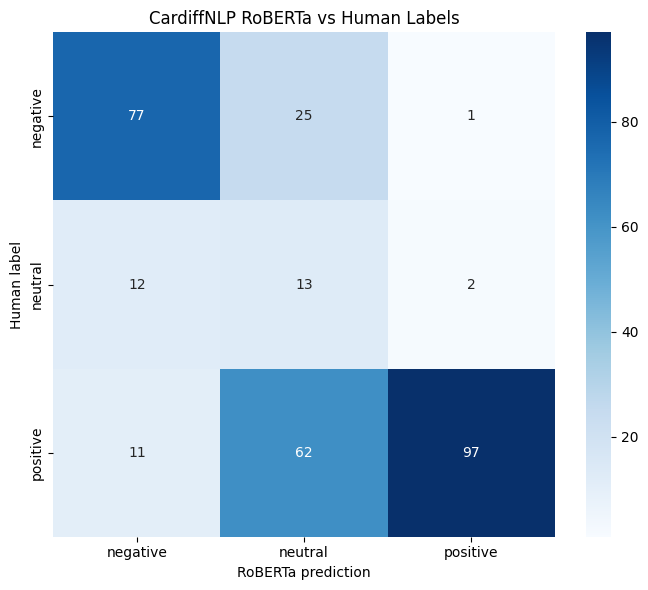

In [46]:
LABEL_ORDER = [
    "negative",
    "neutral",
    "positive"
]

confusion = confusion_matrix(
    y_true,
    y_pred,
    labels=LABEL_ORDER
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=LABEL_ORDER,
    yticklabels=LABEL_ORDER
)

plt.title(
    "CardiffNLP RoBERTa vs Human Labels"
)

plt.xlabel("RoBERTa prediction")
plt.ylabel("Human label")
plt.tight_layout()

CONFUSION_MATRIX_PATH = (
    FIGURE_DIR
    / "roberta_manual_confusion_matrix.png"
)

plt.savefig(
    CONFUSION_MATRIX_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

##Inspect incorrect predictions

This shows the most confident mistakes first. Those cases are useful for documenting model limitations.

In [48]:
roberta_errors = (
    manual_evaluation[
        ~manual_evaluation[
            "prediction_correct"
        ]
    ]
    .sort_values(
        "pseudo_confidence",
        ascending=False
    )
)

print(
    "Incorrect predictions:",
    len(roberta_errors)
)

display(
    roberta_errors[
        [
            "sample_id",
            "model_text",
            "human_label",
            "pseudo_label",
            "pseudo_confidence",
            "text_truncated",

        ]
    ].head(20)
)

Incorrect predictions: 113


,sample_id,model_text,human_label,pseudo_label,pseudo_confidence,text_truncated
256,MVS-0257,Medium level performance. My Mac which is a ye...,neutral,negative,0.869504,False
138,MVS-0139,Action and intonation need improvements The vi...,negative,neutral,0.843833,False
131,MVS-0132,Es bueno Buena cafetera el único problema es q...,positive,neutral,0.843320,False
115,MVS-0116,Beginner Kids Acoustic Guitar The video showca...,positive,neutral,0.826035,False
232,MVS-0233,Step Up In Taste But Leakage I purchased this ...,negative,positive,0.817490,True
165,MVS-0166,10🌟 Es la silla de mis sueños lo tiene todo lo...,positive,neutral,0.810960,False
127,MVS-0128,Inmensa Quedó inmensa,negative,neutral,0.798298,False
252,MVS-0253,"Ultrasonic Toothbrush Not True Electric First,...",positive,neutral,0.795047,True
46,MVS-0047,Very good. But not the greatest. It is fast. B...,neutral,positive,0.791432,False
69,MVS-0070,"Increíble Me encantó esta compra, tiene para c...",positive,neutral,0.789182,False


##Save the evaluation outputs

These files provide the client with evidence that the generated labels were checked manually.

In [49]:
EVALUATION_DATA_PATH = (
    MANUAL_LABEL_DIR
    / "manual_validation_evaluated.csv"
)

METRICS_PATH = (
    REPORT_DIR
    / "roberta_manual_evaluation_metrics.json"
)

CLASS_REPORT_PATH = (
    REPORT_DIR
    / "roberta_manual_classification_report.csv"
)

ERROR_ANALYSIS_PATH = (
    REPORT_DIR
    / "roberta_manual_errors.csv"
)

manual_evaluation.to_csv(
    EVALUATION_DATA_PATH,
    index=False,
    encoding="utf-8-sig"
)

class_report.to_csv(
    CLASS_REPORT_PATH
)

roberta_errors.to_csv(
    ERROR_ANALYSIS_PATH,
    index=False,
    encoding="utf-8-sig"
)

with open(
    METRICS_PATH,
    "w",
    encoding="utf-8"
) as metrics_file:
    json.dump(
        evaluation_metrics,
        metrics_file,
        indent=2
    )

print("Evaluation data:", EVALUATION_DATA_PATH)
print("Metrics:", METRICS_PATH)
print("Class report:", CLASS_REPORT_PATH)
print("Error analysis:", ERROR_ANALYSIS_PATH)

Evaluation data: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/manual_labels/manual_validation_evaluated.csv
Metrics: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/sentiment/roberta_manual_evaluation_metrics.json
Class report: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/sentiment/roberta_manual_classification_report.csv
Error analysis: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/sentiment/roberta_manual_errors.csv


### Human-validation interpretation

This need to be changed later

##Revised Step 4E: Prepare training, validation and final test data

##1. Load the pseudo and human-labelled datasets

In [50]:
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MANUAL_LABEL_DIR = PROJECT_ROOT / "data" / "manual_labels"
REPORT_DIR = PROJECT_ROOT / "reports" / "sentiment"

PSEUDO_LABEL_PATH = (
    PROCESSED_DIR
    / "reviews_pseudo_labeled.csv"
)

MANUAL_EVALUATION_PATH = (
    MANUAL_LABEL_DIR
    / "manual_validation_evaluated.csv"
)

reviews_pseudo = pd.read_csv(
    PSEUDO_LABEL_PATH,
    dtype={"review_id": str},
    keep_default_na=False
)

human_test = pd.read_csv(
    MANUAL_EVALUATION_PATH,
    dtype={
        "sample_id": str,
        "review_id": str
    },
    keep_default_na=False
)

print(
    "Pseudo-labelled reviews:",
    len(reviews_pseudo)
)

print(
    "Human-labelled final test reviews:",
    len(human_test)
)

Pseudo-labelled reviews: 6486
Human-labelled final test reviews: 300


##2. Normalize required fields

This restores the correct data types after reading from CSV.

In [51]:
VALID_LABELS = {
    "negative",
    "neutral",
    "positive"
}

reviews_pseudo["pseudo_label"] = (
    reviews_pseudo["pseudo_label"]
    .astype(str)
    .str.strip()
    .str.lower()
)

human_test["human_label"] = (
    human_test["human_label"]
    .astype(str)
    .str.strip()
    .str.lower()
)

reviews_pseudo["pseudo_confidence"] = (
    pd.to_numeric(
        reviews_pseudo["pseudo_confidence"],
        errors="coerce"
    )
)

reviews_pseudo["confidence_margin"] = (
    pd.to_numeric(
        reviews_pseudo["confidence_margin"],
        errors="coerce"
    )
)

reviews_pseudo["text_truncated"] = (
    reviews_pseudo["text_truncated"]
    .astype(str)
    .str.lower()
    .eq("true")
)

assert set(
    reviews_pseudo["pseudo_label"]
).issubset(VALID_LABELS)

assert set(
    human_test["human_label"]
).issubset(VALID_LABELS)

assert reviews_pseudo["review_id"].is_unique
assert human_test["review_id"].is_unique

print("Field normalization successful.")

Field normalization successful.


##3. Create normalized text keys

Different review IDs can occasionally contain identical text. The normalized key helps prevent that text from appearing in both training and human testing.

In [52]:
def create_text_key(series):
    return (
        series
        .astype(str)
        .str.lower()
        .str.replace(
            r"\s+",
            " ",
            regex=True
        )
        .str.strip()
    )


reviews_pseudo["normalized_text_key"] = (
    create_text_key(
        reviews_pseudo["model_text"]
    )
)

human_test["normalized_text_key"] = (
    create_text_key(
        human_test["model_text"]
    )
)

##4. Exclude all human-tested reviews

The 300 human-labelled reviews must remain completely unseen during training and pseudo-validation.

We exclude both matching review IDs and matching review text.

In [53]:
human_review_ids = set(
    human_test["review_id"]
)

human_text_keys = set(
    human_test["normalized_text_key"]
)

missing_human_review_ids = (
    human_review_ids
    - set(reviews_pseudo["review_id"])
)

if missing_human_review_ids:
    raise ValueError(
        "Some human-labelled reviews are missing "
        "from the pseudo-labelled dataset."
    )

review_id_overlap_mask = (
    reviews_pseudo["review_id"]
    .isin(human_review_ids)
)

text_overlap_mask = (
    reviews_pseudo["normalized_text_key"]
    .isin(human_text_keys)
)

pseudo_development = reviews_pseudo[
    ~review_id_overlap_mask
    & ~text_overlap_mask
].copy()

removed_human_ids = (
    review_id_overlap_mask.sum()
)

additional_text_overlaps_removed = (
    (
        text_overlap_mask
        & ~review_id_overlap_mask
    )
    .sum()
)

print(
    "Human review IDs removed:",
    removed_human_ids
)

print(
    "Additional matching texts removed:",
    additional_text_overlaps_removed
)

print(
    "Pseudo development rows:",
    len(pseudo_development)
)

Human review IDs removed: 300
Additional matching texts removed: 0
Pseudo development rows: 6186


##5. Remove unreliable pseudo-labels

RoBERTa achieved only moderate agreement with humans. Therefore, we train student models using its more reliable predictions.

We exclude:

Confidence below 70%
Truncated text
Empty model text

In [57]:
MINIMUM_CONFIDENCE = 0.70

reliable_pseudo_data = pseudo_development[
    pseudo_development[
        "pseudo_confidence"
    ].ge(MINIMUM_CONFIDENCE)
    & ~pseudo_development[
        "text_truncated"
    ]
    & pseudo_development[
        "model_text"
    ].astype(str).str.strip().ne("")
].copy()

low_quality_rows_removed = (
    len(pseudo_development)
    - len(reliable_pseudo_data)
)

print(
    "Reliable pseudo-labelled reviews:",
    len(reliable_pseudo_data)
)

print(
    "Low-confidence/truncated rows removed:",
    low_quality_rows_removed
)

display(
    reliable_pseudo_data[
        "pseudo_label"
    ].value_counts()
)

Reliable pseudo-labelled reviews: 5290
Low-confidence/truncated rows removed: 896


,count
pseudo_label,
positive,5065
negative,185
neutral,40


##6. Remove exact duplicate training text

This prevents identical text with different review IDs from appearing in training and validation.

In [58]:
rows_before_deduplication = len(
    reliable_pseudo_data
)

reliable_pseudo_data = (
    reliable_pseudo_data
    .drop_duplicates(
        subset=["normalized_text_key"],
        keep="first"
    )
    .reset_index(drop=True)
)

duplicate_text_rows_removed = (
    rows_before_deduplication
    - len(reliable_pseudo_data)
)

print(
    "Exact duplicate texts removed:",
    duplicate_text_rows_removed
)

print(
    "Final pseudo development rows:",
    len(reliable_pseudo_data)
)

Exact duplicate texts removed: 6
Final pseudo development rows: 5284


In [59]:
reliable_class_counts = (
    reliable_pseudo_data[
        "pseudo_label"
    ].value_counts()
)

display(reliable_class_counts)

if (
    reliable_class_counts
    .reindex(
        [
            "negative",
            "neutral",
            "positive"
        ],
        fill_value=0
    )
    .min()
    < 20
):
    raise ValueError(
        "At least one sentiment class has too "
        "few reliable training examples."
    )

,count
pseudo_label,
positive,5059
negative,185
neutral,40


##Create the stratified 80:20 split

The three candidate models will train on the 80% set and be selected using the 20% pseudo-validation set.

In [60]:
SEED = 42

pseudo_train, pseudo_validation = (
    train_test_split(
        reliable_pseudo_data,
        test_size=0.20,
        random_state=SEED,
        stratify=reliable_pseudo_data[
            "pseudo_label"
        ]
    )
)

pseudo_train = (
    pseudo_train
    .copy()
    .reset_index(drop=True)
)

pseudo_validation = (
    pseudo_validation
    .copy()
    .reset_index(drop=True)
)

print(
    "Pseudo training rows:",
    len(pseudo_train)
)

print(
    "Pseudo validation rows:",
    len(pseudo_validation)
)

Pseudo training rows: 4227
Pseudo validation rows: 1057


##8. Display the split distributions

This confirms that stratification preserved every sentiment class.

In [61]:
split_distribution = pd.concat(
    [
        pseudo_train[
            "pseudo_label"
        ].value_counts().rename(
            "pseudo_train"
        ),

        pseudo_validation[
            "pseudo_label"
        ].value_counts().rename(
            "pseudo_validation"
        ),

        human_test[
            "human_label"
        ].value_counts().rename(
            "human_final_test"
        )
    ],
    axis=1
).fillna(0).astype(int)

split_distribution = (
    split_distribution
    .reindex(
        [
            "negative",
            "neutral",
            "positive"
        ]
    )
)

display(split_distribution)

,pseudo_train,pseudo_validation,human_final_test
negative,148,37,103
neutral,32,8,27
positive,4047,1012,170


##9. Validate that no data leakage exists

This confirms that no review ID or exact text is shared between the datasets.

In [62]:
train_review_ids = set(
    pseudo_train["review_id"]
)

validation_review_ids = set(
    pseudo_validation["review_id"]
)

train_text_keys = set(
    pseudo_train["normalized_text_key"]
)

validation_text_keys = set(
    pseudo_validation[
        "normalized_text_key"
    ]
)

assert train_review_ids.isdisjoint(
    validation_review_ids
)

assert train_review_ids.isdisjoint(
    human_review_ids
)

assert validation_review_ids.isdisjoint(
    human_review_ids
)

assert train_text_keys.isdisjoint(
    validation_text_keys
)

assert train_text_keys.isdisjoint(
    human_text_keys
)

assert validation_text_keys.isdisjoint(
    human_text_keys
)

print("All dataset splits are disjoint.")
print("No review ID or exact-text leakage detected.")

All dataset splits are disjoint.
No review ID or exact-text leakage detected.


##10. Save the three final datasets

The saved files contain only the fields required for training, selection and evaluation.

In [64]:
PSEUDO_OUTPUT_COLUMNS = [
    "review_id",
    "category",
    "model_text",
    "pseudo_label",
    "pseudo_confidence",
    "confidence_margin"
]

HUMAN_TEST_COLUMNS = [
    "sample_id",
    "review_id",
    "category",
    "model_text",
    "human_label",
    "pseudo_label",
    "pseudo_confidence",
    "review_rating",
]

PSEUDO_TRAIN_PATH = (
    PROCESSED_DIR
    / "sentiment_pseudo_train.csv"
)

PSEUDO_VALIDATION_PATH = (
    PROCESSED_DIR
    / "sentiment_pseudo_validation.csv"
)

HUMAN_TEST_PATH = (
    MANUAL_LABEL_DIR
    / "sentiment_human_test.csv"
)

pseudo_train[
    PSEUDO_OUTPUT_COLUMNS
].to_csv(
    PSEUDO_TRAIN_PATH,
    index=False,
    encoding="utf-8-sig"
)

pseudo_validation[
    PSEUDO_OUTPUT_COLUMNS
].to_csv(
    PSEUDO_VALIDATION_PATH,
    index=False,
    encoding="utf-8-sig"
)

human_test[
    HUMAN_TEST_COLUMNS
].to_csv(
    HUMAN_TEST_PATH,
    index=False,
    encoding="utf-8-sig"
)

split_distribution.to_csv(
    REPORT_DIR
    / "sentiment_split_distribution.csv"
)

print("Pseudo training:", PSEUDO_TRAIN_PATH)
print("Pseudo validation:", PSEUDO_VALIDATION_PATH)
print("Human final test:", HUMAN_TEST_PATH)

Pseudo training: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/sentiment_pseudo_train.csv
Pseudo validation: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/sentiment_pseudo_validation.csv
Human final test: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/manual_labels/sentiment_human_test.csv


##11. Create the preparation summary

This records how many rows were removed and how the final datasets were created.

In [65]:
preparation_summary = pd.DataFrame({
    "metric": [
        "Total unique pseudo-labelled reviews",
        "Human-labelled reviews excluded",
        "Additional matching texts excluded",
        "Low-confidence/truncated reviews excluded",
        "Duplicate training texts excluded",
        "Pseudo training rows",
        "Pseudo validation rows",
        "Human final test rows"
    ],
    "value": [
        len(reviews_pseudo),
        removed_human_ids,
        additional_text_overlaps_removed,
        low_quality_rows_removed,
        duplicate_text_rows_removed,
        len(pseudo_train),
        len(pseudo_validation),
        len(human_test)
    ]
})

display(preparation_summary)

preparation_summary.to_csv(
    REPORT_DIR
    / "sentiment_training_preparation_summary.csv",
    index=False
)

,metric,value
0,Total unique pseudo-labelled reviews,6486
1,Human-labelled reviews excluded,300
2,Additional matching texts excluded,0
3,Low-confidence/truncated reviews excluded,896
4,Duplicate training texts excluded,6
5,Pseudo training rows,4227
6,Pseudo validation rows,1057
7,Human final test rows,300


### Final training-data preparation

The 6,486 unique RoBERTa-labelled reviews were divided into pseudo-labelled model-development data and a human-labelled final benchmark.

All 300 manually labelled reviews were excluded from training and pseudo-validation. Reviews containing the same normalized text as a human-tested review were also excluded to prevent leakage.

Pseudo-labelled reviews below 70% confidence, reviews truncated by the teacher tokenizer and exact duplicate text were excluded from student-model training. These records remain available in the complete application dataset.

The remaining reliable pseudo-labelled reviews were divided into 80% training and 20% validation sets using stratified sampling. Naive Bayes, Logistic Regression and Linear SVM will train only on the 80% pseudo-labelled set.

Models will be selected using macro-F1 on the 20% pseudo-validation set. The 300 human-labelled reviews will not influence training, hyperparameter tuning or model selection. They will be used only to report final human-verified performance.

After grid search, the fitted `best_estimator_` will be evaluated and saved directly. No separate retraining on combined training and validation data will be performed.

## This checks the currently saved manual files and shows how many pseudo-labels remain at different confidence thresholds.

In [66]:
from pathlib import Path
import pandas as pd

COMPLETED_PATH = (
    MANUAL_LABEL_DIR
    / "manual_validation_completed.csv"
)

EVALUATED_PATH = (
    MANUAL_LABEL_DIR
    / "manual_validation_evaluated.csv"
)

completed_audit = pd.read_csv(
    COMPLETED_PATH,
    dtype={
        "sample_id": str,
        "review_id": str
    },
    keep_default_na=False
)

evaluated_audit = pd.read_csv(
    EVALUATED_PATH,
    dtype={
        "sample_id": str,
        "review_id": str
    },
    keep_default_na=False
)

for dataframe in [
    completed_audit,
    evaluated_audit
]:
    dataframe["human_label"] = (
        dataframe["human_label"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

print("COMPLETED FILE")
print("Rows:", len(completed_audit))
print(
    completed_audit[
        "human_label"
    ].value_counts()
)

print("\nEVALUATED FILE")
print("Rows:", len(evaluated_audit))
print(
    evaluated_audit[
        "human_label"
    ].value_counts()
)

label_comparison = (
    completed_audit[
        [
            "sample_id",
            "review_id",
            "human_label"
        ]
    ]
    .merge(
        evaluated_audit[
            [
                "sample_id",
                "review_id",
                "human_label"
            ]
        ],
        on=[
            "sample_id",
            "review_id"
        ],
        how="outer",
        suffixes=(
            "_completed",
            "_evaluated"
        ),
        indicator=True
    )
)

label_mismatches = label_comparison[
    (
        label_comparison["_merge"]
        != "both"
    )
    | (
        label_comparison[
            "human_label_completed"
        ]
        != label_comparison[
            "human_label_evaluated"
        ]
    )
]

print(
    "\nCompleted/evaluated mismatches:",
    len(label_mismatches)
)

COMPLETED FILE
Rows: 300
human_label
positive    170
negative    103
neutral      27
Name: count, dtype: int64

EVALUATED FILE
Rows: 300
human_label
positive    170
negative    103
neutral      27
Name: count, dtype: int64

Completed/evaluated mismatches: 0


In [67]:
threshold_rows = []

for threshold in [
    0.00,
    0.50,
    0.60,
    0.70,
    0.80,
    0.90
]:
    threshold_data = pseudo_development[
        pseudo_development[
            "pseudo_confidence"
        ].ge(threshold)
        & ~pseudo_development[
            "text_truncated"
        ]
    ]

    counts = (
        threshold_data[
            "pseudo_label"
        ]
        .value_counts()
    )

    threshold_rows.append({
        "confidence_threshold": threshold,
        "negative": counts.get(
            "negative",
            0
        ),
        "neutral": counts.get(
            "neutral",
            0
        ),
        "positive": counts.get(
            "positive",
            0
        ),
        "total": len(threshold_data)
    })

confidence_threshold_summary = pd.DataFrame(
    threshold_rows
)

display(confidence_threshold_summary)

,confidence_threshold,negative,neutral,positive,total
0,0.0,299,201,5392,5892
1,0.5,275,143,5315,5733
2,0.6,223,68,5207,5498
3,0.7,185,40,5065,5290
4,0.8,137,19,4829,4985
5,0.9,63,1,4262,4326


##Step 4F: Train and compare baseline models
New Section
Now we will train three classical sentiment models using the pseudo-labelled training set:

Complement Naive Bayes
Logistic Regression
Linear SVM

All models use TF-IDF review features. Class imbalance is handled during training, and model comparison uses the untouched pseudo-validation set. We will not use the 300 human-labelled reviews yet.

## 4F.1 — Load the prepared datasets

Add a new section below Step 4E and run this cell:

In [68]:
# ============================================================
# Step 4F.1: Load prepared sentiment datasets
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports" / "sentiment"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = PROCESSED_DIR / "sentiment_pseudo_train.csv"
VALIDATION_PATH = (
    PROCESSED_DIR / "sentiment_pseudo_validation.csv"
)

pseudo_train = pd.read_csv(TRAIN_PATH)
pseudo_validation = pd.read_csv(VALIDATION_PATH)

TEXT_COLUMN = "model_text"
TARGET_COLUMN = "pseudo_label"
LABELS = ["negative", "neutral", "positive"]

required_columns = {TEXT_COLUMN, TARGET_COLUMN}

for dataset_name, dataframe in {
    "training": pseudo_train,
    "validation": pseudo_validation,
}.items():
    missing_columns = required_columns - set(dataframe.columns)

    if missing_columns:
        raise ValueError(
            f"{dataset_name} dataset is missing: "
            f"{sorted(missing_columns)}"
        )

    dataframe[TEXT_COLUMN] = (
        dataframe[TEXT_COLUMN]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    dataframe[TARGET_COLUMN] = (
        dataframe[TARGET_COLUMN]
        .astype(str)
        .str.lower()
        .str.strip()
    )

print("Training rows:", len(pseudo_train))
print("Validation rows:", len(pseudo_validation))

display(
    pd.DataFrame({
        "training": (
            pseudo_train[TARGET_COLUMN]
            .value_counts()
            .reindex(LABELS, fill_value=0)
        ),
        "validation": (
            pseudo_validation[TARGET_COLUMN]
            .value_counts()
            .reindex(LABELS, fill_value=0)
        ),
    })
)

Training rows: 4227
Validation rows: 1057


,training,validation
pseudo_label,,
negative,148,37
neutral,32,8
positive,4047,1012


## 4F.2 — Define the baseline models

This cell creates a separate TF-IDF pipeline for each model. Logistic Regression and SVM use balanced class weights. Complement Naive Bayes will receive balanced sample weights during training.

In [69]:
# ============================================================
# Step 4F.2: Define baseline model pipelines
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.utils.class_weight import compute_sample_weight

X_train = pseudo_train[TEXT_COLUMN]
y_train = pseudo_train[TARGET_COLUMN]

X_validation = pseudo_validation[TEXT_COLUMN]
y_validation = pseudo_validation[TARGET_COLUMN]

train_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

def create_tfidf():
    return TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        max_features=50_000,
        sublinear_tf=True
    )

baseline_models = {
    "Complement Naive Bayes": Pipeline([
        ("tfidf", create_tfidf()),
        ("classifier", ComplementNB(alpha=1.0))
    ]),

    "Logistic Regression": Pipeline([
        ("tfidf", create_tfidf()),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=2_000,
                random_state=42
            )
        )
    ]),

    "Linear SVM": Pipeline([
        ("tfidf", create_tfidf()),
        (
            "classifier",
            LinearSVC(
                class_weight="balanced",
                random_state=42
            )
        )
    ])
}

print("Models prepared:")
for model_name in baseline_models:
    print("-", model_name)

Models prepared:
- Complement Naive Bayes
- Logistic Regression
- Linear SVM


## 4F.3 — Train and evaluate the models

This cell trains each model once and compares them using macro-F1, balanced accuracy, and class-level F1 scores.

In [70]:
# ============================================================
# Step 4F.3: Train and evaluate baseline models
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

baseline_results = []
baseline_predictions = pd.DataFrame({
    "true_label": y_validation.reset_index(drop=True)
})

trained_baseline_models = {}

for model_name, model_pipeline in baseline_models.items():

    print(f"Training: {model_name}")

    if model_name == "Complement Naive Bayes":
        model_pipeline.fit(
            X_train,
            y_train,
            classifier__sample_weight=train_sample_weights
        )
    else:
        model_pipeline.fit(X_train, y_train)

    predictions = model_pipeline.predict(X_validation)

    class_f1 = f1_score(
        y_validation,
        predictions,
        labels=LABELS,
        average=None,
        zero_division=0
    )

    baseline_results.append({
        "model": model_name,
        "accuracy": accuracy_score(
            y_validation, predictions
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_validation, predictions
        ),
        "macro_precision": precision_score(
            y_validation,
            predictions,
            average="macro",
            zero_division=0
        ),
        "macro_recall": recall_score(
            y_validation,
            predictions,
            average="macro",
            zero_division=0
        ),
        "macro_f1": f1_score(
            y_validation,
            predictions,
            average="macro",
            zero_division=0
        ),
        "negative_f1": class_f1[0],
        "neutral_f1": class_f1[1],
        "positive_f1": class_f1[2]
    })

    baseline_predictions[model_name] = predictions
    trained_baseline_models[model_name] = model_pipeline

baseline_comparison = (
    pd.DataFrame(baseline_results)
    .sort_values(
        by=["macro_f1", "balanced_accuracy"],
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    baseline_comparison.style.format({
        column: "{:.4f}"
        for column in baseline_comparison.columns
        if column != "model"
    })
)

Training: Complement Naive Bayes
Training: Logistic Regression
Training: Linear SVM


,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,negative_f1,neutral_f1,positive_f1
0,Logistic Regression,0.9678,0.8433,0.7136,0.8433,0.7261,0.7576,0.4375,0.9831
1,Linear SVM,0.9669,0.6061,0.7907,0.6061,0.6390,0.4898,0.4444,0.9829
2,Complement Naive Bayes,0.9149,0.9030,0.5317,0.9030,0.6167,0.4964,0.4000,0.9537


## 4F.4 — Save the baseline results

We are saving only the comparison and predictions now. The final model will be saved after grid search.

In [71]:


BASELINE_RESULTS_PATH = (
    REPORT_DIR / "baseline_model_comparison.csv"
)

BASELINE_PREDICTIONS_PATH = (
    REPORT_DIR / "baseline_validation_predictions.csv"
)

baseline_comparison.to_csv(
    BASELINE_RESULTS_PATH,
    index=False
)

baseline_predictions.to_csv(
    BASELINE_PREDICTIONS_PATH,
    index=False
)

print("Baseline comparison saved to:")
print(BASELINE_RESULTS_PATH)

print("\nValidation predictions saved to:")
print(BASELINE_PREDICTIONS_PATH)

Baseline comparison saved to:
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/sentiment/baseline_model_comparison.csv

Validation predictions saved to:
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/sentiment/baseline_validation_predictions.csv


##Step 4G: Grid-search fine-tuning

Now we will fine-tune all three baseline models. Grid search will test a small set of meaningful hyperparameters using only pseudo_train.

The process is:

Perform three-fold stratified cross-validation inside pseudo_train.
Select each model’s best parameters using macro-F1.
Evaluate each tuned model once on pseudo_validation.
Keep the 300 human-labelled reviews untouched.

## 4G.1 — Configure grid search

In [80]:
# ============================================================
# Step 4G.1: Configure grid-search fine-tuning
# ============================================================

from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV, StratifiedKFold

if "baseline_models" not in globals():
    raise RuntimeError(
        "Run Step 4F before starting Step 4G."
    )

# Use scikit-learn's built-in macro-F1 scorer.
GRID_SCORING = "f1_macro"

stratified_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

parameter_grids = {
    "Complement Naive Bayes": {
        "tfidf__ngram_range": [
            (1, 1),
            (1, 2)
        ],
        "classifier__alpha": [
            0.1,
            0.5,
            1.0,
            2.0
        ]
    },

    "Logistic Regression": {
        "tfidf__ngram_range": [
            (1, 1),
            (1, 2)
        ],
        "classifier__C": [
            0.1,
            0.5,
            1.0,
            2.0,
            5.0
        ]
    },

    "Linear SVM": {
        "tfidf__ngram_range": [
            (1, 1),
            (1, 2)
        ],
        "classifier__C": [
            0.1,
            0.5,
            1.0,
            2.0,
            5.0
        ]
    }
}

print("Grid-search configuration prepared.")
print("Cross-validation folds:", stratified_cv.n_splits)

Grid-search configuration prepared.
Cross-validation folds: 3


## 4G.2 — Run grid search

refit=True means that after finding the best settings, GridSearchCV automatically fits that model once on the complete pseudo-training set. We will not manually train it again.

In [81]:
# ============================================================
# Step 4G.2: Fine-tune all candidate models
# ============================================================

import json
import numpy as np
import pandas as pd

tuned_models = {}
grid_search_objects = {}
grid_search_rows = []
all_cv_results = []

for model_name, model_pipeline in baseline_models.items():

    print("\n" + "=" * 60)
    print(f"Fine-tuning: {model_name}")
    print("=" * 60)

    grid_search = GridSearchCV(
        estimator=model_pipeline,
        param_grid=parameter_grids[model_name],
        scoring=GRID_SCORING,
        cv=stratified_cv,
        n_jobs=-1,
        refit=True,
        verbose=1,
        return_train_score=False,
        error_score="raise"
    )

    fit_parameters = {}

    if model_name == "Complement Naive Bayes":
        fit_parameters["classifier__sample_weight"] = (
            train_sample_weights
        )

    grid_search.fit(
        X_train,
        y_train,
        **fit_parameters
    )

    if not np.isfinite(grid_search.best_score_):
        raise ValueError(
            f"Grid search failed for {model_name}: "
            "best CV score is not finite."
        )

    best_model = grid_search.best_estimator_

    validation_predictions = best_model.predict(
        X_validation
    )

    class_f1 = f1_score(
        y_validation,
        validation_predictions,
        labels=LABELS,
        average=None,
        zero_division=0
    )

    grid_search_rows.append({
        "model": model_name,
        "internal_cv_macro_f1": grid_search.best_score_,

        "validation_accuracy": accuracy_score(
            y_validation,
            validation_predictions
        ),

        "validation_balanced_accuracy":
            balanced_accuracy_score(
                y_validation,
                validation_predictions
            ),

        "validation_macro_precision": precision_score(
            y_validation,
            validation_predictions,
            average="macro",
            zero_division=0
        ),

        "validation_macro_recall": recall_score(
            y_validation,
            validation_predictions,
            average="macro",
            zero_division=0
        ),

        "validation_macro_f1": f1_score(
            y_validation,
            validation_predictions,
            average="macro",
            zero_division=0
        ),

        "negative_f1": class_f1[0],
        "neutral_f1": class_f1[1],
        "positive_f1": class_f1[2],

        "best_parameters": json.dumps(
            grid_search.best_params_
        )
    })

    model_cv_results = pd.DataFrame(
        grid_search.cv_results_
    )[
        [
            "params",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].copy()

    model_cv_results.insert(
        0,
        "model",
        model_name
    )

    model_cv_results["params"] = (
        model_cv_results["params"]
        .apply(json.dumps)
    )

    all_cv_results.append(model_cv_results)

    tuned_models[model_name] = best_model
    grid_search_objects[model_name] = grid_search

    print(
        "Best CV macro-F1:",
        round(grid_search.best_score_, 4)
    )

    print(
        "Best parameters:",
        grid_search.best_params_
    )


Fine-tuning: Complement Naive Bayes
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best CV macro-F1: 0.6261
Best parameters: {'classifier__alpha': 0.5, 'tfidf__ngram_range': (1, 2)}

Fine-tuning: Logistic Regression
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best CV macro-F1: 0.7331
Best parameters: {'classifier__C': 0.5, 'tfidf__ngram_range': (1, 1)}

Fine-tuning: Linear SVM
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best CV macro-F1: 0.6712
Best parameters: {'classifier__C': 1.0, 'tfidf__ngram_range': (1, 1)}


4G.3 — Compare tuned models

The models are ranked by validation macro-F1. Balanced accuracy is used as the secondary ranking metric

In [82]:
# ============================================================
# Step 4G.3: Compare tuned models
# ============================================================

tuned_comparison = (
    pd.DataFrame(grid_search_rows)
    .sort_values(
        by=[
            "validation_macro_f1",
            "validation_balanced_accuracy"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

numeric_columns = [
    column
    for column in tuned_comparison.columns
    if column not in ["model", "best_parameters"]
]

display(
    tuned_comparison.style.format({
        column: "{:.4f}"
        for column in numeric_columns
    })
)

,model,internal_cv_macro_f1,validation_accuracy,validation_balanced_accuracy,validation_macro_precision,validation_macro_recall,validation_macro_f1,negative_f1,neutral_f1,positive_f1,best_parameters
0,Logistic Regression,0.7331,0.9508,0.8981,0.6024,0.8981,0.6859,0.6598,0.4242,0.9738,"{""classifier__C"": 0.5, ""tfidf__ngram_range"": [1, 1]}"
1,Complement Naive Bayes,0.6261,0.9413,0.8948,0.5770,0.8948,0.6637,0.5981,0.4242,0.9686,"{""classifier__alpha"": 0.5, ""tfidf__ngram_range"": [1, 2]}"
2,Linear SVM,0.6712,0.9640,0.6572,0.6778,0.6572,0.6579,0.5714,0.4211,0.9813,"{""classifier__C"": 1.0, ""tfidf__ngram_range"": [1, 1]}"


## 4G.4 — Save grid-search results

These files document the tuning process. We are not saving the final application model yet.

In [83]:
# ============================================================
# Step 4G.4: Save fine-tuning results
# ============================================================

TUNED_COMPARISON_PATH = (
    REPORT_DIR / "tuned_model_comparison.csv"
)

CV_RESULTS_PATH = (
    REPORT_DIR / "grid_search_cv_results.csv"
)

complete_cv_results = pd.concat(
    all_cv_results,
    ignore_index=True
)

tuned_comparison.to_csv(
    TUNED_COMPARISON_PATH,
    index=False
)

complete_cv_results.to_csv(
    CV_RESULTS_PATH,
    index=False
)

print("Tuned comparison saved to:")
print(TUNED_COMPARISON_PATH)

print("\nComplete grid-search results saved to:")
print(CV_RESULTS_PATH)

Tuned comparison saved to:
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/sentiment/tuned_model_comparison.csv

Complete grid-search results saved to:
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/sentiment/grid_search_cv_results.csv


## Step 4H: Final human evaluation and model saving
We will now select the baseline Logistic Regression model because it achieved the highest pseudo-validation macro-F1 (0.7261).

The model will not be retrained. We will evaluate the already-trained pipeline once on the 300 human-labelled reviews and then save the complete TF-IDF + Logistic Regression pipeline for Streamlit.

## 4H.1 — Load the final human-test dataset

In [86]:
# ============================================================
# Step 4H.1: Select model and load human final test
# ============================================================

from pathlib import Path
import pandas as pd

FINAL_MODEL_NAME = "Logistic Regression"

if FINAL_MODEL_NAME not in trained_baseline_models:
    raise RuntimeError(
        "The baseline Logistic Regression model is unavailable. "
        "Run Step 4F again."
    )

final_model = trained_baseline_models[FINAL_MODEL_NAME]

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

MANUAL_LABEL_DIR = (
    PROJECT_ROOT / "data" / "manual_labels"
)

HUMAN_TEST_PATH = (
    MANUAL_LABEL_DIR / "sentiment_human_test.csv"
)

if not HUMAN_TEST_PATH.exists():
    raise FileNotFoundError(
        f"Human-test file was not found: {HUMAN_TEST_PATH}"
    )

human_test = pd.read_csv(
    HUMAN_TEST_PATH,
    dtype={
        "sample_id": str,
        "review_id": str
    },
    keep_default_na=False
)

TEXT_COLUMN = "model_text"
HUMAN_TARGET_COLUMN = "human_label"
LABELS = ["negative", "neutral", "positive"]

required_columns = {
    TEXT_COLUMN,
    HUMAN_TARGET_COLUMN
}

missing_columns = (
    required_columns - set(human_test.columns)
)

if missing_columns:
    raise ValueError(
        f"Human-test dataset is missing: "
        f"{sorted(missing_columns)}"
    )

human_test[TEXT_COLUMN] = (
    human_test[TEXT_COLUMN]
    .astype(str)
    .str.strip()
)

human_test[HUMAN_TARGET_COLUMN] = (
    human_test[HUMAN_TARGET_COLUMN]
    .astype(str)
    .str.lower()
    .str.strip()
)

invalid_labels = (
    set(human_test[HUMAN_TARGET_COLUMN].unique())
    - set(LABELS)
)

if invalid_labels:
    raise ValueError(
        f"Invalid human labels found: {invalid_labels}"
    )

print("Selected model:", FINAL_MODEL_NAME)
print("Human-test file:", HUMAN_TEST_PATH)
print("Human-test rows:", len(human_test))

display(
    human_test[HUMAN_TARGET_COLUMN]
    .value_counts()
    .reindex(LABELS, fill_value=0)
    .rename("count")
    .to_frame()
)

Selected model: Logistic Regression
Human-test file: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/manual_labels/sentiment_human_test.csv
Human-test rows: 300


,count
human_label,
negative,103
neutral,27
positive,170


## 4H.2 — Evaluate on human labels

This is the final real-world evaluation. Model selection must not be changed based on this result.

In [87]:
# ============================================================
# Step 4H.2: Evaluate final model on human labels
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score
)

X_human_test = human_test[TEXT_COLUMN]
y_human_test = human_test[HUMAN_TARGET_COLUMN]

human_predictions_array = final_model.predict(
    X_human_test
)

human_probabilities = final_model.predict_proba(
    X_human_test
)

final_metrics = pd.DataFrame([{
    "model": FINAL_MODEL_NAME,
    "accuracy": accuracy_score(
        y_human_test,
        human_predictions_array
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_human_test,
        human_predictions_array
    ),
    "macro_precision": precision_score(
        y_human_test,
        human_predictions_array,
        average="macro",
        zero_division=0
    ),
    "macro_recall": recall_score(
        y_human_test,
        human_predictions_array,
        average="macro",
        zero_division=0
    ),
    "macro_f1": f1_score(
        y_human_test,
        human_predictions_array,
        average="macro",
        zero_division=0
    ),
    "weighted_f1": f1_score(
        y_human_test,
        human_predictions_array,
        average="weighted",
        zero_division=0
    )
}])

human_classification_report = pd.DataFrame(
    classification_report(
        y_human_test,
        human_predictions_array,
        labels=LABELS,
        target_names=LABELS,
        output_dict=True,
        zero_division=0
    )
).transpose()

display(
    final_metrics.style.format({
        column: "{:.4f}"
        for column in final_metrics.columns
        if column != "model"
    })
)

display(
    human_classification_report.style.format(
        "{:.4f}"
    )
)

,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,Logistic Regression,0.6867,0.4806,0.5497,0.4806,0.4908,0.6693


,precision,recall,f1-score,support
negative,0.9123,0.5049,0.6500,103.0000
neutral,0.0476,0.0370,0.0417,27.0000
positive,0.6892,0.9000,0.7806,170.0000
accuracy,0.6867,0.6867,0.6867,0.6867
macro avg,0.5497,0.4806,0.4908,300.0000
weighted avg,0.7080,0.6867,0.6693,300.0000


## 4H.3 — Create the confusion matrix

This shows exactly where the final model confuses negative, neutral and positive reviews.

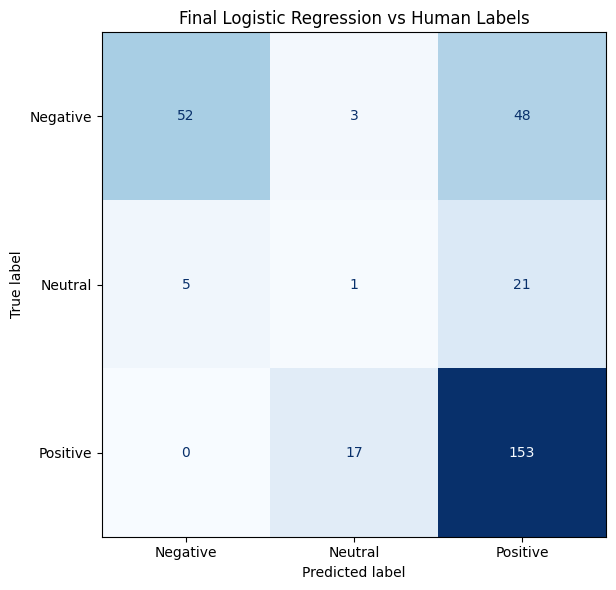

In [88]:
# ============================================================
# Step 4H.3: Final human-test confusion matrix
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

CONFUSION_MATRIX_PATH = (
    REPORT_DIR / "final_human_confusion_matrix.png"
)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_human_test,
    human_predictions_array,
    labels=LABELS,
    display_labels=[
        "Negative",
        "Neutral",
        "Positive"
    ],
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title(
    "Final Logistic Regression vs Human Labels"
)

plt.tight_layout()
plt.savefig(
    CONFUSION_MATRIX_PATH,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 4H.4 — Save predictions, model and metadata

The saved .joblib file contains both TF-IDF preprocessing and the classifier. Streamlit can therefore receive raw review text and call model.predict() directly.

In [89]:
# ============================================================
# Step 4H.4: Save final model and evaluation artifacts
# ============================================================

import json
import joblib
import sklearn

from datetime import datetime, timezone

MODEL_DIR = PROJECT_ROOT / "models" / "sentiment"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

FINAL_MODEL_PATH = (
    MODEL_DIR / "sentiment_model.joblib"
)

MODEL_METADATA_PATH = (
    MODEL_DIR / "sentiment_model_metadata.json"
)

FINAL_METRICS_PATH = (
    REPORT_DIR / "final_human_test_metrics.csv"
)

FINAL_REPORT_PATH = (
    REPORT_DIR / "final_human_classification_report.csv"
)

FINAL_PREDICTIONS_PATH = (
    REPORT_DIR / "final_human_test_predictions.csv"
)

# Save predictions and probability scores
human_predictions = human_test.copy()

human_predictions["predicted_sentiment"] = (
    human_predictions_array
)

classifier_classes = (
    final_model
    .named_steps["classifier"]
    .classes_
)

for class_index, class_name in enumerate(
    classifier_classes
):
    human_predictions[
        f"probability_{class_name}"
    ] = human_probabilities[:, class_index]

human_predictions["prediction_correct"] = (
    human_predictions["predicted_sentiment"]
    == human_predictions[HUMAN_TARGET_COLUMN]
)

# Save complete TF-IDF + classifier pipeline
joblib.dump(
    final_model,
    FINAL_MODEL_PATH
)

final_metrics.to_csv(
    FINAL_METRICS_PATH,
    index=False
)

human_classification_report.to_csv(
    FINAL_REPORT_PATH
)

human_predictions.to_csv(
    FINAL_PREDICTIONS_PATH,
    index=False,
    encoding="utf-8-sig"
)

tfidf_model = final_model.named_steps["tfidf"]
classifier_model = final_model.named_steps["classifier"]

model_metadata = {
    "model_name": "TF-IDF Logistic Regression",
    "model_version": "1.0",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "text_column": TEXT_COLUMN,
    "output_labels": LABELS,
    "pseudo_label_confidence_threshold": 0.70,
    "training_rows": len(pseudo_train),
    "pseudo_validation_rows": len(
        pseudo_validation
    ),
    "human_test_rows": len(human_test),
    "selection_metric": "pseudo-validation macro-F1",
    "selection_score": 0.7261,
    "tfidf_parameters": {
        "ngram_range": list(
            tfidf_model.ngram_range
        ),
        "min_df": tfidf_model.min_df,
        "max_df": tfidf_model.max_df,
        "max_features": tfidf_model.max_features,
        "sublinear_tf": tfidf_model.sublinear_tf
    },
    "classifier_parameters": {
        "classifier": "LogisticRegression",
        "C": classifier_model.C,
        "class_weight": classifier_model.class_weight,
        "max_iter": classifier_model.max_iter
    },
    "human_test_metrics": {
        column: float(final_metrics.iloc[0][column])
        for column in final_metrics.columns
        if column != "model"
    },
    "scikit_learn_version": sklearn.__version__,
    "joblib_version": joblib.__version__
}

with open(
    MODEL_METADATA_PATH,
    "w",
    encoding="utf-8"
) as metadata_file:
    json.dump(
        model_metadata,
        metadata_file,
        indent=2
    )

print("Final model saved to:")
print(FINAL_MODEL_PATH)

print("\nModel metadata saved to:")
print(MODEL_METADATA_PATH)

print("\nFinal evaluation artifacts saved successfully.")

Final model saved to:
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/sentiment/sentiment_model.joblib

Model metadata saved to:
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/sentiment/sentiment_model_metadata.json

Final evaluation artifacts saved successfully.


## Final Model Findings and Deployment Decision

### Objective

The sentiment-analysis pipeline was developed to classify Amazon reviews into three classes: **negative**, **neutral**, and **positive**. CardiffNLP RoBERTa was initially used as the teacher model to generate pseudo-labels for 6,486 unique reviews. Reviews with confidence below 0.70, truncated reviews, duplicates, and the 300 manually labelled reviews were excluded from classical-model training.

Three classical models were then developed and compared:

* Complement Naive Bayes
* Logistic Regression
* Linear SVM

TF-IDF was used to convert review text into numerical features. Class weighting or balanced sample weighting was applied to reduce the effect of class imbalance. Macro-F1 was used as the primary model-selection metric because accuracy alone can be misleading for this dataset.

### Classical-model findings

Among the classical models, baseline Logistic Regression achieved the highest pseudo-validation macro-F1.

| Model                  | Pseudo-validation Macro-F1 |
| ---------------------- | -------------------------: |
| Logistic Regression    |                 **0.7261** |
| Linear SVM             |                     0.6390 |
| Complement Naive Bayes |                     0.6167 |

Grid-search fine-tuning was also performed for all three models. However, the tuned Logistic Regression model achieved a lower pseudo-validation macro-F1 of 0.6859. Therefore, the original baseline Logistic Regression remained the best classical candidate.

This result demonstrates that fine-tuning does not always improve generalization. The grid-search experiment was retained as evidence of systematic hyperparameter evaluation.

### Logistic Regression human-test performance

The selected baseline Logistic Regression model was evaluated once against 300 manually labelled reviews that were excluded from training and pseudo-validation.

| Metric            | Result |
| ----------------- | -----: |
| Accuracy          | 0.6867 |
| Balanced accuracy | 0.4806 |
| Macro-F1          | 0.4908 |
| Weighted F1       | 0.6693 |
| Negative F1       | 0.6500 |
| Neutral F1        | 0.0417 |
| Positive F1       | 0.7806 |

The model correctly classified:

* 52 of 103 negative reviews
* 1 of 27 neutral reviews
* 153 of 170 positive reviews

Although its overall accuracy was 68.67%, the model performed poorly across the three classes. In particular, it failed to recognize neutral sentiment reliably and incorrectly classified many negative and neutral reviews as positive.

The difference between its pseudo-validation macro-F1 of 0.7261 and human-test macro-F1 of 0.4908 indicates that Logistic Regression learned to imitate the pseudo-label patterns but did not transfer sufficiently well to human sentiment interpretation.

### RoBERTa human-evaluation performance

CardiffNLP RoBERTa was evaluated against the same 300 manually labelled reviews.

| Metric            | Result |
| ----------------- | -----: |
| Accuracy          | 0.6233 |
| Balanced accuracy | 0.5999 |
| Macro-F1          | 0.5606 |
| Weighted F1       | 0.6860 |
| Negative F1       | 0.7586 |
| Neutral F1        | 0.2047 |
| Positive F1       | 0.7185 |

RoBERTa had lower overall accuracy than Logistic Regression, but it achieved better:

* Balanced accuracy
* Macro-F1
* Weighted F1
* Negative F1
* Neutral F1

Logistic Regression obtained higher accuracy mainly because it predicted the majority positive class more frequently. Since the required application must distinguish all three sentiment classes, macro-F1 and balanced accuracy are more appropriate than accuracy for the deployment decision.

### Final decision

Logistic Regression will be retained as the **best classical baseline/student model**. Its trained TF-IDF and Logistic Regression pipeline, model metadata, pseudo-validation results, grid-search results, human-test metrics, and confusion matrix will be preserved as experimental artifacts.

However, Logistic Regression will not be used as the primary application inference model because its neutral F1 of 0.0417 demonstrates that it cannot currently provide dependable three-class sentiment predictions.

CardiffNLP RoBERTa will be used as the **application inference model** because it provides better performance across the sentiment classes, particularly for negative and neutral reviews. Its contextual language representation also makes it more suitable for handling negation, mixed opinions, and relationships between words than a TF-IDF-based classifier.

### Streamlit application behavior

The Streamlit sentiment-analysis feature will use RoBERTa predictions for:

* Sentiment overview
* Product-level sentiment analysis
* Keyword/category sentiment summaries
* Custom-review classification

Previously generated RoBERTa predictions can be loaded directly for the collected review dataset. For newly entered custom reviews, the application will run RoBERTa inference and return:

* Predicted sentiment
* Confidence score
* Probability for each sentiment class
* A low-confidence warning when appropriate

The Logistic Regression model will remain available as an experimental comparison model, but its predictions will not be exposed as the primary sentiment result.

### Known limitation

Neutral sentiment remains difficult even for RoBERTa. Its neutral F1 is 0.2047, which is better than Logistic Regression but still low. Neutral and mixed reviews should therefore be interpreted cautiously, particularly when prediction confidence is low.

This limitation is caused by factors including:

* A naturally positive-heavy Amazon review distribution
* Few reliable neutral pseudo-labels
* Mixed-sentiment reviews
* Differences between RoBERTa pseudo-labels and human interpretation
* Limited manually labelled neutral examples

Low-confidence predictions should be marked as uncertain rather than presented as fully reliable.

### Future improvement

A future custom sentiment model should be developed using additional manually labelled negative and neutral reviews. A new independent human test set would also be required because the current 300 reviews have already been used for final evaluation and the deployment decision.

Possible future improvements include:

* Collecting more human-labelled neutral and mixed reviews
* Using targeted minority-class sampling
* Fine-tuning a transformer directly on Amazon review text
* Applying confidence calibration
* Introducing an uncertain or mixed-sentiment output
* Performing aspect-level sentiment analysis

### Final conclusion

The experiment successfully compared multiple classical sentiment models, applied class-imbalance handling, performed grid-search fine-tuning, and evaluated the selected student model against manually labelled reviews.

Logistic Regression remains the best classical baseline, but the final human evaluation shows that it is unsuitable as the primary three-class inference model. CardiffNLP RoBERTa is therefore selected for Streamlit inference because it provides more balanced performance and better agreement with human labels across negative, neutral, and positive sentiment.


## Step 4I: Save the deployment models correctly

Now we will:

* Preserve Logistic Regression as the best classical candidate.
* Save RoBERTa and its tokenizer locally inside the project.
* Create metadata explaining which model Streamlit should use.
* Keep the existing Logistic Regression files unchanged for safety.

In [90]:
# ============================================================
# Step 4I.1: Save classical candidate and RoBERTa deployment model
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import json
import shutil
import torch
import transformers

from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer
)

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

MODEL_DIR = PROJECT_ROOT / "models" / "sentiment"

CLASSICAL_MODEL_DIR = (
    MODEL_DIR / "classical_candidate"
)

ROBERTA_MODEL_DIR = (
    MODEL_DIR / "roberta_inference"
)

CLASSICAL_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

ROBERTA_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 1. Preserve the Logistic Regression experiment
# ------------------------------------------------------------

CURRENT_LR_MODEL_PATH = (
    MODEL_DIR / "sentiment_model.joblib"
)

CURRENT_LR_METADATA_PATH = (
    MODEL_DIR / "sentiment_model_metadata.json"
)

LR_CANDIDATE_PATH = (
    CLASSICAL_MODEL_DIR
    / "logistic_regression_candidate.joblib"
)

LR_CANDIDATE_METADATA_PATH = (
    CLASSICAL_MODEL_DIR
    / "logistic_regression_candidate_metadata.json"
)

if CURRENT_LR_MODEL_PATH.exists():
    shutil.copy2(
        CURRENT_LR_MODEL_PATH,
        LR_CANDIDATE_PATH
    )
else:
    raise FileNotFoundError(
        f"Logistic Regression model not found: "
        f"{CURRENT_LR_MODEL_PATH}"
    )

if CURRENT_LR_METADATA_PATH.exists():
    shutil.copy2(
        CURRENT_LR_METADATA_PATH,
        LR_CANDIDATE_METADATA_PATH
    )

# ------------------------------------------------------------
# 2. Load RoBERTa if it is unavailable in memory
# ------------------------------------------------------------

ROBERTA_MODEL_NAME = (
    "cardiffnlp/"
    "twitter-roberta-base-sentiment-latest"
)

if "tokenizer" not in globals():
    tokenizer = AutoTokenizer.from_pretrained(
        ROBERTA_MODEL_NAME
    )

if "labeling_model" not in globals():
    labeling_model = (
        AutoModelForSequenceClassification
        .from_pretrained(ROBERTA_MODEL_NAME)
    )

# ------------------------------------------------------------
# 3. Save RoBERTa model and tokenizer
# ------------------------------------------------------------

labeling_model.save_pretrained(
    ROBERTA_MODEL_DIR,
    safe_serialization=True
)

tokenizer.save_pretrained(
    ROBERTA_MODEL_DIR
)

# ------------------------------------------------------------
# 4. Save deployment-decision metadata
# ------------------------------------------------------------

DEPLOYMENT_METADATA_PATH = (
    MODEL_DIR / "deployment_metadata.json"
)

deployment_metadata = {
    "deployment_model": (
        "cardiffnlp/"
        "twitter-roberta-base-sentiment-latest"
    ),
    "deployment_model_directory": (
        "models/sentiment/roberta_inference"
    ),
    "classical_candidate": (
        "TF-IDF Logistic Regression"
    ),
    "classical_candidate_directory": (
        "models/sentiment/classical_candidate"
    ),
    "output_labels": [
        "negative",
        "neutral",
        "positive"
    ],
    "streamlit_inference_model": "RoBERTa",
    "maximum_token_length": 512,
    "low_confidence_warning_threshold": 0.70,
    "selection_reason": (
        "RoBERTa achieved better human-test macro-F1, "
        "balanced accuracy, negative F1 and neutral F1."
    ),
    "roberta_human_metrics": {
        "accuracy": 0.6233,
        "balanced_accuracy": 0.5999,
        "macro_f1": 0.5606,
        "weighted_f1": 0.6860,
        "negative_f1": 0.7586,
        "neutral_f1": 0.2047,
        "positive_f1": 0.7185
    },
    "logistic_regression_human_metrics": {
        "accuracy": 0.6867,
        "balanced_accuracy": 0.4806,
        "macro_f1": 0.4908,
        "weighted_f1": 0.6693,
        "negative_f1": 0.6500,
        "neutral_f1": 0.0417,
        "positive_f1": 0.7806
    },
    "known_limitation": (
        "Neutral sentiment remains difficult even for "
        "RoBERTa. Low-confidence predictions should be "
        "presented as uncertain."
    ),
    "transformers_version": transformers.__version__,
    "pytorch_version": torch.__version__,
    "saved_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

with open(
    DEPLOYMENT_METADATA_PATH,
    "w",
    encoding="utf-8"
) as metadata_file:
    json.dump(
        deployment_metadata,
        metadata_file,
        indent=2
    )

print("Logistic Regression candidate saved to:")
print(LR_CANDIDATE_PATH)

print("\nRoBERTa inference model saved to:")
print(ROBERTA_MODEL_DIR)

print("\nDeployment metadata saved to:")
print(DEPLOYMENT_METADATA_PATH)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Logistic Regression candidate saved to:
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/sentiment/classical_candidate/logistic_regression_candidate.joblib

RoBERTa inference model saved to:
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/sentiment/roberta_inference

Deployment metadata saved to:
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/sentiment/deployment_metadata.json


# Step 4I.2: Verify the saved RoBERTa model

In [91]:
# ============================================================
# Step 4I.2: Verify saved RoBERTa inference model
# ============================================================

from pathlib import Path

import pandas as pd
import torch

from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer
)

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

ROBERTA_MODEL_DIR = (
    PROJECT_ROOT
    / "models"
    / "sentiment"
    / "roberta_inference"
)

REPORT_DIR = (
    PROJECT_ROOT
    / "reports"
    / "sentiment"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

if not ROBERTA_MODEL_DIR.exists():
    raise FileNotFoundError(
        f"Saved RoBERTa model not found: "
        f"{ROBERTA_MODEL_DIR}"
    )

# Load only from the saved project directory.
deployment_tokenizer = AutoTokenizer.from_pretrained(
    ROBERTA_MODEL_DIR,
    local_files_only=True
)

deployment_model = (
    AutoModelForSequenceClassification
    .from_pretrained(
        ROBERTA_MODEL_DIR,
        local_files_only=True
    )
    .to("cpu")
)

deployment_model.eval()

print("Saved model loaded successfully from:")
print(ROBERTA_MODEL_DIR)

print("\nLabel mapping:")
print(deployment_model.config.id2label)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Saved model loaded successfully from:
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/sentiment/roberta_inference

Label mapping:
{0: 'negative', 1: 'neutral', 2: 'positive'}


In [92]:
# ============================================================
# Step 4I.3: Create and test inference function
# ============================================================

LOW_CONFIDENCE_THRESHOLD = 0.70
MAX_LENGTH = 512

def predict_sentiment(review_text):

    cleaned_text = str(review_text).strip()

    if not cleaned_text:
        raise ValueError(
            "Review text cannot be empty."
        )

    model_inputs = deployment_tokenizer(
        cleaned_text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    )

    with torch.inference_mode():
        model_outputs = deployment_model(
            **model_inputs
        )

    probabilities = torch.softmax(
        model_outputs.logits,
        dim=-1
    )[0].cpu().numpy()

    predicted_index = int(
        probabilities.argmax()
    )

    predicted_label = (
        deployment_model
        .config
        .id2label[predicted_index]
        .lower()
    )

    probability_scores = {
        deployment_model
        .config
        .id2label[index]
        .lower(): float(score)
        for index, score in enumerate(probabilities)
    }

    confidence = float(
        probabilities[predicted_index]
    )

    return {
        "predicted_sentiment": predicted_label,
        "confidence": confidence,
        "low_confidence": (
            confidence
            < LOW_CONFIDENCE_THRESHOLD
        ),
        "negative_probability": (
            probability_scores["negative"]
        ),
        "neutral_probability": (
            probability_scores["neutral"]
        ),
        "positive_probability": (
            probability_scores["positive"]
        )
    }


test_reviews = [
    "Excellent sound quality and amazing battery life.",
    "The product is okay, but nothing particularly special.",
    "It stopped working after only two days."
]

verification_results = []

for review in test_reviews:
    prediction = predict_sentiment(review)

    verification_results.append({
        "review_text": review,
        **prediction
    })

verification_table = pd.DataFrame(
    verification_results
)

display(
    verification_table.style.format({
        "confidence": "{:.4f}",
        "negative_probability": "{:.4f}",
        "neutral_probability": "{:.4f}",
        "positive_probability": "{:.4f}"
    })
)

,review_text,predicted_sentiment,confidence,low_confidence,negative_probability,neutral_probability,positive_probability
0,Excellent sound quality and amazing battery life.,positive,0.9757,False,0.0054,0.0190,0.9757
1,"The product is okay, but nothing particularly special.",negative,0.5944,True,0.5944,0.3667,0.0388
2,It stopped working after only two days.,negative,0.7797,False,0.7797,0.2077,0.0126


In [93]:
# ============================================================
# Step 4I.4: Save inference verification report
# ============================================================

VERIFICATION_REPORT_PATH = (
    REPORT_DIR
    / "roberta_inference_verification.csv"
)

verification_table.to_csv(
    VERIFICATION_REPORT_PATH,
    index=False,
    encoding="utf-8-sig"
)

assert set(
    verification_table["predicted_sentiment"]
).issubset({
    "negative",
    "neutral",
    "positive"
})

probability_sums = (
    verification_table[
        [
            "negative_probability",
            "neutral_probability",
            "positive_probability"
        ]
    ]
    .sum(axis=1)
)

assert probability_sums.between(
    0.999,
    1.001
).all()

print("Inference verification successful.")
print("Verification report saved to:")
print(VERIFICATION_REPORT_PATH)

Inference verification successful.
Verification report saved to:
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/sentiment/roberta_inference_verification.csv


##Step 4J: Prepare Streamlit sentiment datasets

Now we will convert the modeling outputs into application-ready datasets.

Three files will be created:

Review-level sentiment data for detailed review tables
Product-level sentiment summaries
Keyword/category-level sentiment summaries

Shared reviews remain attached to every applicable ASIN for product analysis. For keyword summaries, shared reviews are counted only once per keyword to avoid inflation.

## 4J.1 — Merge RoBERTa predictions with all product reviews

In [94]:
# ============================================================
# Step 4J.1: Create application review-level dataset
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports" / "sentiment"

REVIEWS_CLEAN_PATH = (
    PROCESSED_DIR / "reviews_clean.csv"
)

PRODUCTS_CLEAN_PATH = (
    PROCESSED_DIR / "products_clean.csv"
)

PREDICTIONS_PATH = (
    PROCESSED_DIR / "reviews_pseudo_labeled.csv"
)

REVIEWS_APP_PATH = (
    PROCESSED_DIR / "reviews_sentiment_app.csv"
)

reviews_clean = pd.read_csv(
    REVIEWS_CLEAN_PATH,
    dtype={
        "asin": str,
        "review_id": str
    },
    keep_default_na=False
)

products_clean = pd.read_csv(
    PRODUCTS_CLEAN_PATH,
    dtype={"asin": str},
    keep_default_na=False
)

roberta_predictions = pd.read_csv(
    PREDICTIONS_PATH,
    dtype={"review_id": str},
    keep_default_na=False
)

prediction_columns = [
    "review_id",
    "pseudo_label",
    "pseudo_confidence",
    "negative_score",
    "neutral_score",
    "positive_score"
]

missing_prediction_columns = (
    set(prediction_columns)
    - set(roberta_predictions.columns)
)

if missing_prediction_columns:
    raise ValueError(
        "Prediction file is missing: "
        f"{sorted(missing_prediction_columns)}"
    )

review_predictions = (
    roberta_predictions[prediction_columns]
    .drop_duplicates(
        subset=["review_id"],
        keep="first"
    )
    .rename(columns={
        "pseudo_label": "sentiment_label",
        "pseudo_confidence": "sentiment_confidence",
        "negative_score": "negative_probability",
        "neutral_score": "neutral_probability",
        "positive_score": "positive_probability"
    })
)

if not review_predictions["review_id"].is_unique:
    raise ValueError(
        "Prediction review IDs must be unique."
    )

reviews_sentiment_app = reviews_clean.merge(
    review_predictions,
    on="review_id",
    how="left",
    validate="many_to_one"
)

missing_predictions = (
    reviews_sentiment_app["sentiment_label"]
    .isna()
    .sum()
)

if missing_predictions:
    raise ValueError(
        f"{missing_predictions} review associations "
        "do not have RoBERTa predictions."
    )

reviews_sentiment_app[
    "sentiment_low_confidence"
] = (
    reviews_sentiment_app[
        "sentiment_confidence"
    ].lt(0.70)
)

reviews_sentiment_app[
    "sentiment_model"
] = (
    "cardiffnlp/"
    "twitter-roberta-base-sentiment-latest"
)

reviews_sentiment_app.to_csv(
    REVIEWS_APP_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Review-level application rows:")
print(len(reviews_sentiment_app))

print("\nSaved to:")
print(REVIEWS_APP_PATH)

Review-level application rows:
7595

Saved to:
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/reviews_sentiment_app.csv


## 4J.2 — Create a reusable summary function

In [95]:
# ============================================================
# Step 4J.2: Define sentiment summary function
# ============================================================

SENTIMENT_LABELS = [
    "negative",
    "neutral",
    "positive"
]

def create_sentiment_summary(
    dataframe,
    group_column
):
    sentiment_counts = pd.crosstab(
        dataframe[group_column],
        dataframe["sentiment_label"]
    ).reindex(
        columns=SENTIMENT_LABELS,
        fill_value=0
    )

    sentiment_counts = sentiment_counts.rename(
        columns={
            label: f"{label}_count"
            for label in SENTIMENT_LABELS
        }
    )

    summary_metrics = (
        dataframe
        .groupby(group_column)
        .agg(
            review_count=(
                "review_id",
                "count"
            ),
            average_sentiment_confidence=(
                "sentiment_confidence",
                "mean"
            )
        )
    )

    summary = (
        summary_metrics
        .join(sentiment_counts)
        .reset_index()
    )

    count_columns = [
        f"{label}_count"
        for label in SENTIMENT_LABELS
    ]

    for label in SENTIMENT_LABELS:
        summary[f"{label}_percentage"] = (
            summary[f"{label}_count"]
            .div(summary["review_count"])
            .mul(100)
            .round(2)
        )

    summary["dominant_sentiment"] = (
        summary[count_columns]
        .idxmax(axis=1)
        .str.replace(
            "_count",
            "",
            regex=False
        )
    )

    summary[
        "average_sentiment_confidence"
    ] = (
        summary[
            "average_sentiment_confidence"
        ].round(4)
    )

    return summary

## 4J.3 — Create product-level summaries

Products without reviews are retained and marked as no_reviews.

In [96]:
# ============================================================
# Step 4J.3: Create product-level sentiment summary
# ============================================================

PRODUCT_SUMMARY_PATH = (
    PROCESSED_DIR
    / "product_sentiment_summary.csv"
)

product_sentiment_metrics = (
    create_sentiment_summary(
        reviews_sentiment_app,
        "asin"
    )
)

preferred_product_columns = [
    "asin",
    "category",
    "title",
    "brand",
    "price",
    "avg_rating",
    "rating_count",
    "product_url",
    "image_url"
]

available_product_columns = [
    column
    for column in preferred_product_columns
    if column in products_clean.columns
]

product_information = (
    products_clean[available_product_columns]
    .drop_duplicates(
        subset=["asin"],
        keep="first"
    )
)

product_sentiment_summary = (
    product_information
    .merge(
        product_sentiment_metrics,
        on="asin",
        how="left",
        validate="one_to_one"
    )
)

count_columns = [
    "review_count",
    "negative_count",
    "neutral_count",
    "positive_count"
]

percentage_columns = [
    "negative_percentage",
    "neutral_percentage",
    "positive_percentage"
]

for column in count_columns:
    product_sentiment_summary[column] = (
        product_sentiment_summary[column]
        .fillna(0)
        .astype(int)
    )

for column in percentage_columns:
    product_sentiment_summary[column] = (
        product_sentiment_summary[column]
        .fillna(0.0)
    )

product_sentiment_summary[
    "dominant_sentiment"
] = (
    product_sentiment_summary[
        "dominant_sentiment"
    ].fillna("no_reviews")
)

product_sentiment_summary["has_reviews"] = (
    product_sentiment_summary["review_count"] > 0
)

product_sentiment_summary.to_csv(
    PRODUCT_SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Product summary rows:")
print(len(product_sentiment_summary))

print("Products without reviews:")
print(
    (~product_sentiment_summary["has_reviews"])
    .sum()
)

print("\nSaved to:")
print(PRODUCT_SUMMARY_PATH)

Product summary rows:
981
Products without reviews:
20

Saved to:
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/product_sentiment_summary.csv


# 4J.4 — Create keyword/category summaries

The category field represents the search keyword, as previously decided. A shared review is counted only once inside each keyword.

In [97]:
# ============================================================
# Step 4J.4: Create keyword/category sentiment summary
# ============================================================

KEYWORD_SUMMARY_PATH = (
    PROCESSED_DIR
    / "keyword_sentiment_summary.csv"
)

keyword_unique_reviews = (
    reviews_sentiment_app
    .drop_duplicates(
        subset=[
            "category",
            "review_id"
        ],
        keep="first"
    )
    .copy()
)

keyword_sentiment_summary = (
    create_sentiment_summary(
        keyword_unique_reviews,
        "category"
    )
)

keyword_product_counts = (
    products_clean
    .groupby("category")["asin"]
    .nunique()
    .rename("product_count")
    .reset_index()
)

keyword_sentiment_summary = (
    keyword_product_counts
    .merge(
        keyword_sentiment_summary,
        on="category",
        how="left",
        validate="one_to_one"
    )
)

keyword_sentiment_summary = (
    keyword_sentiment_summary
    .sort_values(
        "review_count",
        ascending=False
    )
    .reset_index(drop=True)
)

keyword_sentiment_summary.to_csv(
    KEYWORD_SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("Keyword/category summary rows:")
print(len(keyword_sentiment_summary))

print("\nSaved to:")
print(KEYWORD_SUMMARY_PATH)

display(
    keyword_sentiment_summary.head(10)
)

Keyword/category summary rows:
28

Saved to:
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/keyword_sentiment_summary.csv


,category,product_count,review_count,average_sentiment_confidence,negative_count,neutral_count,positive_count,negative_percentage,neutral_percentage,positive_percentage,dominant_sentiment
0,sneakers,60,448,0.8773,26,23,399,5.80,5.13,89.06,positive
1,sunglasses,57,422,0.8867,28,20,374,6.64,4.74,88.63,positive
2,yamaha accoustic guitar,56,389,0.8769,31,32,326,7.97,8.23,83.80,positive
3,candle,52,378,0.9177,43,10,325,11.38,2.65,85.98,positive
4,desk lamp LED,49,375,0.8942,9,19,347,2.40,5.07,92.53,positive
5,notebook journal,55,368,0.9287,3,13,352,0.82,3.53,95.65,positive
6,gaming chair,55,353,0.8720,42,23,288,11.90,6.52,81.59,positive
7,kitchen knife set,54,352,0.9206,18,5,329,5.11,1.42,93.47,positive
8,water bottle,58,344,0.8870,16,11,317,4.65,3.20,92.15,positive
9,t-shirt,57,336,0.8855,21,15,300,6.25,4.46,89.29,positive


## 4J.5 — Validate and record outputs

In [98]:
# ============================================================
# Step 4J.5: Validate application datasets
# ============================================================

application_data_summary = pd.DataFrame({
    "dataset": [
        "Review-level sentiment",
        "Product-level sentiment",
        "Keyword/category sentiment"
    ],
    "rows": [
        len(reviews_sentiment_app),
        len(product_sentiment_summary),
        len(keyword_sentiment_summary)
    ],
    "saved_path": [
        str(REVIEWS_APP_PATH),
        str(PRODUCT_SUMMARY_PATH),
        str(KEYWORD_SUMMARY_PATH)
    ]
})

assert len(reviews_sentiment_app) == len(
    reviews_clean
)

assert product_sentiment_summary[
    "asin"
].is_unique

assert keyword_sentiment_summary[
    "category"
].is_unique

assert reviews_sentiment_app[
    "sentiment_label"
].isin(SENTIMENT_LABELS).all()

display(application_data_summary)

APPLICATION_SUMMARY_PATH = (
    REPORT_DIR
    / "application_sentiment_data_summary.csv"
)

application_data_summary.to_csv(
    APPLICATION_SUMMARY_PATH,
    index=False
)

print("Application data preparation successful.")

,dataset,rows,saved_path
0,Review-level sentiment,7595,/content/drive/MyDrive/Amazon-Marketplace-Prod...
1,Product-level sentiment,981,/content/drive/MyDrive/Amazon-Marketplace-Prod...
2,Keyword/category sentiment,28,/content/drive/MyDrive/Amazon-Marketplace-Prod...


Application data preparation successful.


# Step 4K: Final artifact validation

This is the final Colab notebook step. It verifies that all application data and model files exist and creates a manifest describing what Streamlit should load.

In [99]:
# ============================================================
# Step 4K: Validate and document final sentiment artifacts
# ============================================================

from datetime import datetime, timezone
from pathlib import Path

import json
import numpy as np

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MANUAL_LABEL_DIR = PROJECT_ROOT / "data" / "manual_labels"
MODEL_DIR = PROJECT_ROOT / "models" / "sentiment"
REPORT_DIR = PROJECT_ROOT / "reports" / "sentiment"

required_artifacts = {
    "review_sentiment_data": (
        PROCESSED_DIR / "reviews_sentiment_app.csv"
    ),
    "product_sentiment_summary": (
        PROCESSED_DIR / "product_sentiment_summary.csv"
    ),
    "keyword_sentiment_summary": (
        PROCESSED_DIR / "keyword_sentiment_summary.csv"
    ),
    "human_test_data": (
        MANUAL_LABEL_DIR / "sentiment_human_test.csv"
    ),
    "logistic_regression_candidate": (
        MODEL_DIR
        / "classical_candidate"
        / "logistic_regression_candidate.joblib"
    ),
    "roberta_config": (
        MODEL_DIR
        / "roberta_inference"
        / "config.json"
    ),
    "roberta_tokenizer_config": (
        MODEL_DIR
        / "roberta_inference"
        / "tokenizer_config.json"
    ),
    "deployment_metadata": (
        MODEL_DIR / "deployment_metadata.json"
    )
}

artifact_status = {
    artifact_name: artifact_path.exists()
    for artifact_name, artifact_path
    in required_artifacts.items()
}

# RoBERTa may use safetensors or a PyTorch binary.
roberta_weight_files = (
    list(
        (
            MODEL_DIR / "roberta_inference"
        ).glob("*.safetensors")
    )
    + list(
        (
            MODEL_DIR / "roberta_inference"
        ).glob("*.bin")
    )
)

artifact_status["roberta_model_weights"] = (
    len(roberta_weight_files) > 0
)

failed_artifacts = [
    artifact_name
    for artifact_name, exists
    in artifact_status.items()
    if not exists
]

if failed_artifacts:
    raise FileNotFoundError(
        "Missing required artifacts: "
        f"{failed_artifacts}"
    )

# Validate application dataset relationships.
assert len(reviews_sentiment_app) == 7595
assert len(product_sentiment_summary) == 981
assert len(keyword_sentiment_summary) == 28

assert reviews_sentiment_app[
    "sentiment_label"
].isin([
    "negative",
    "neutral",
    "positive"
]).all()

assert product_sentiment_summary[
    "asin"
].is_unique

assert keyword_sentiment_summary[
    "category"
].is_unique

probability_columns = [
    "negative_probability",
    "neutral_probability",
    "positive_probability"
]

probability_sums = (
    reviews_sentiment_app[
        probability_columns
    ]
    .sum(axis=1)
)

assert np.allclose(
    probability_sums,
    1.0,
    atol=1e-4
)

sentiment_distribution = (
    reviews_sentiment_app[
        "sentiment_label"
    ]
    .value_counts()
    .reindex(
        [
            "negative",
            "neutral",
            "positive"
        ],
        fill_value=0
    )
)

low_confidence_count = int(
    reviews_sentiment_app[
        "sentiment_low_confidence"
    ].sum()
)

products_without_reviews = int(
    (
        ~product_sentiment_summary[
            "has_reviews"
        ]
    ).sum()
)

manifest = {
    "feature": "sentiment_analysis",
    "pipeline_status": "completed",
    "deployment_model": (
        "cardiffnlp/"
        "twitter-roberta-base-sentiment-latest"
    ),
    "classical_candidate": (
        "TF-IDF Logistic Regression"
    ),
    "application_data": {
        "review_association_rows": int(
            len(reviews_sentiment_app)
        ),
        "product_rows": int(
            len(product_sentiment_summary)
        ),
        "keyword_rows": int(
            len(keyword_sentiment_summary)
        ),
        "products_without_reviews": (
            products_without_reviews
        ),
        "sentiment_distribution": {
            label: int(count)
            for label, count
            in sentiment_distribution.items()
        },
        "low_confidence_rows": (
            low_confidence_count
        )
    },
    "application_files": {
        name: str(
            path.relative_to(PROJECT_ROOT)
        )
        for name, path
        in required_artifacts.items()
    },
    "roberta_weight_files": [
        str(path.relative_to(PROJECT_ROOT))
        for path in roberta_weight_files
    ],
    "application_behavior": {
        "sentiment_overview": "RoBERTa predictions",
        "product_analysis": "RoBERTa predictions",
        "keyword_summary": "RoBERTa predictions",
        "custom_review_classifier": "RoBERTa inference",
        "low_confidence_threshold": 0.70
    },
    "known_limitation": (
        "Neutral sentiment performance remains limited. "
        "Low-confidence results must be marked as uncertain."
    ),
    "validated_at_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

MANIFEST_PATH = (
    MODEL_DIR / "sentiment_artifact_manifest.json"
)

with open(
    MANIFEST_PATH,
    "w",
    encoding="utf-8"
) as manifest_file:
    json.dump(
        manifest,
        manifest_file,
        indent=2
    )

artifact_validation_table = pd.DataFrame({
    "artifact": artifact_status.keys(),
    "available": artifact_status.values()
})

display(artifact_validation_table)

print("Final sentiment pipeline validation successful.")
print("Manifest saved to:")
print(MANIFEST_PATH)

,artifact,available
0,review_sentiment_data,True
1,product_sentiment_summary,True
2,keyword_sentiment_summary,True
3,human_test_data,True
4,logistic_regression_candidate,True
5,roberta_config,True
6,roberta_tokenizer_config,True
7,deployment_metadata,True
8,roberta_model_weights,True


Final sentiment pipeline validation successful.
Manifest saved to:
/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/models/sentiment/sentiment_artifact_manifest.json
